In [1]:
!pip install torch --break-system-packages
!pip install transformers --break-system-packages
!pip install datasets --break-system-packages
!pip install accelerate --break-system-packages
!pip install matplotlib --break-system-packages
!pip install seaborn --break-system-packages
!pip install pandas --break-system-packages
!pip install numpy --break-system-packages


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from transformers import GPTNeoXForCausalLM, AutoTokenizer
from collections import OrderedDict
import json

In [3]:
#loading the Pythia-410
model_name = "EleutherAI/pythia-410m"

print(f"\nLoading model: {model_name}")
model = GPTNeoXForCausalLM.from_pretrained(
    model_name,
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
)

`torch_dtype` is deprecated! Use `dtype` instead!



Loading model: EleutherAI/pythia-410m


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [4]:
tokenizer = AutoTokenizer.from_pretrained(model_name)
model.eval()

# Move to GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
print(device)

cpu


In [5]:
config = model.config
head_dim = config.hidden_size // config.num_attention_heads

# RoPE handling (GPT-NeoX / Pythia)
rotary_pct = getattr(config, "rotary_pct", 1.0)   # в Pythia есть rotary full
rotary_dim = int(rotary_pct * head_dim)
rotary_base = getattr(config, "rotary_emb_base", 10000)

print("\nBasic Architecture")
print(f"Model Type: {config.model_type}")
print("Architecture: GPT-NeoX (decoder-only transformer)")
print("Layer Norm Style: Pre-LN")
print("Embedding Weight Tying: Yes")
print("Linear Layer Biases: No")

print("\nLayer Structure")
print(f"Number of Layers: {config.num_hidden_layers}")
print(f"Number of Attention Heads per Layer: {config.num_attention_heads}")
print(f"Total Attention Heads: {config.num_hidden_layers * config.num_attention_heads}")

print("\n--- Dimensions ---")
print(f"Hidden Size (d_model): {config.hidden_size}")
print(f"Head Dimension (d_head): {head_dim}")
print(f"FFN Hidden Size: {config.intermediate_size}")
print(f"Vocabulary Size: {config.vocab_size}")
print(f"Max Context Length: {config.max_position_embeddings}")

print("\nAttention Configuration ")
print("Attention Type: Causal multi-head self-attention")
print("Positional Encoding: Rotary Positional Embeddings (RoPE)")
print(f"Rotary Dimension: {rotary_dim}")
print(f"Rotary Base (theta): {rotary_base}")

print("\n Normalization & Activation")
print(f"LayerNorm Epsilon: {config.layer_norm_eps}")
print(f"Activation Function: {config.hidden_act}")

print("\n--- Regularization ---")
print(f"Dropout: {getattr(config, 'hidden_dropout_prob', 0.0)}")

print("\n--- Initialization ---")
print(f"Initializer Range: {config.initializer_range}")



Basic Architecture
Model Type: gpt_neox
Architecture: GPT-NeoX (decoder-only transformer)
Layer Norm Style: Pre-LN
Embedding Weight Tying: Yes
Linear Layer Biases: No

Layer Structure
Number of Layers: 24
Number of Attention Heads per Layer: 16
Total Attention Heads: 384

--- Dimensions ---
Hidden Size (d_model): 1024
Head Dimension (d_head): 64
FFN Hidden Size: 4096
Vocabulary Size: 50304
Max Context Length: 2048

Attention Configuration 
Attention Type: Causal multi-head self-attention
Positional Encoding: Rotary Positional Embeddings (RoPE)
Rotary Dimension: 16
Rotary Base (theta): 10000

 Normalization & Activation
LayerNorm Epsilon: 1e-05
Activation Function: gelu

--- Regularization ---
Dropout: 0.0

--- Initialization ---
Initializer Range: 0.02


In [6]:
config_dict = config.to_dict()
with open('pythia_410m_config.json', 'w') as f:
    json.dump(config_dict, f, indent=2)
print("pythia_410m_config.json")
# ARCHITECTURAL GROUNDING


print("PART 2: MODULE TREE (NETWORK STRUCTURE)")


def print_module_tree(module, prefix="", max_depth=4, current_depth=0):
    """
    Print hierarchical structure of model modules
    """
    if current_depth >= max_depth:
        return

    # Get all named children
    children = list(module.named_children())

    for idx, (name, child) in enumerate(children):
        # Determine if this is the last child
        is_last = (idx == len(children) - 1)

        # Create tree branch characters
        if is_last:
            branch = "└── "
            extension = "    "
        else:
            branch = "├── "
            extension = "│   "

        # Print current module
        module_type = child.__class__.__name__

        # Count parameters in this module
        num_params = sum(p.numel() for p in child.parameters())
        param_str = f" ({num_params:,} params)" if num_params > 0 else ""

        print(f"{prefix}{branch}{name}: {module_type}{param_str}")

        # Recursively print children
        print_module_tree(
            child,
            prefix + extension,
            max_depth,
            current_depth + 1
        )

print("\nFull Module Tree (Depth 4)\n")
print_module_tree(model, max_depth=4)

pythia_410m_config.json
PART 2: MODULE TREE (NETWORK STRUCTURE)

Full Module Tree (Depth 4)

├── gpt_neox: GPTNeoXModel (353,822,720 params)
│   ├── embed_in: Embedding (51,511,296 params)
│   ├── emb_dropout: Dropout
│   ├── layers: ModuleList (302,309,376 params)
│   │   ├── 0: GPTNeoXLayer (12,596,224 params)
│   │   │   ├── input_layernorm: LayerNorm (2,048 params)
│   │   │   ├── post_attention_layernorm: LayerNorm (2,048 params)
│   │   │   ├── post_attention_dropout: Dropout
│   │   │   ├── post_mlp_dropout: Dropout
│   │   │   ├── attention: GPTNeoXAttention (4,198,400 params)
│   │   │   └── mlp: GPTNeoXMLP (8,393,728 params)
│   │   ├── 1: GPTNeoXLayer (12,596,224 params)
│   │   │   ├── input_layernorm: LayerNorm (2,048 params)
│   │   │   ├── post_attention_layernorm: LayerNorm (2,048 params)
│   │   │   ├── post_attention_dropout: Dropout
│   │   │   ├── post_mlp_dropout: Dropout
│   │   │   ├── attention: GPTNeoXAttention (4,198,400 params)
│   │   │   └── mlp: GPTNeoXMLP

In [7]:
def count_parameters_by_component(model):
    """
    Count parameters for each major component
    """
    param_counts = {
        'Embedding': 0,
        'Attention': 0,
        'Feed-Forward': 0,
        'Layer Norm': 0,
        'Output': 0,
        'Total': 0
    }

    for name, param in model.named_parameters():
        num_params = param.numel()
        param_counts['Total'] += num_params

        if 'embed' in name.lower():
            param_counts['Embedding'] += num_params
        elif 'attention' in name.lower() or 'attn' in name.lower():
            param_counts['Attention'] += num_params
        elif 'mlp' in name.lower() or 'dense' in name.lower():
            param_counts['Feed-Forward'] += num_params
        elif 'ln' in name.lower() or 'norm' in name.lower():
            param_counts['Layer Norm'] += num_params
        elif 'lm_head' in name.lower() or 'output' in name.lower():
            param_counts['Output'] += num_params

    return param_counts

param_counts = count_parameters_by_component(model)

print("\nParameter Distribution")
for component, count in param_counts.items():
    percentage = (count / param_counts['Total'] * 100) if param_counts['Total'] > 0 else 0
    print(f"{component:20s}: {count:15,d} params ({percentage:6.2f}%)")


# DETAILED LAYER-BY-LAYER BREAKDOWN


print("\nLayer-by-Layer Breakdown ")

def analyze_layer_structure(model):
    """
Analyze parameter count for each layer
    """
    layer_info = []

    for layer_idx in range(config.num_hidden_layers):
        layer = model.gpt_neox.layers[layer_idx]

        # Count attention parameters
        attn_params = sum(p.numel() for p in layer.attention.parameters())

        # Count MLP parameters
        mlp_params = sum(p.numel() for p in layer.mlp.parameters())

        # Count layer norm parameters
        ln_params = sum(p.numel() for p in layer.input_layernorm.parameters())
        ln_params += sum(p.numel() for p in layer.post_attention_layernorm.parameters())

        total_layer = attn_params + mlp_params + ln_params

        layer_info.append({
            'Layer': layer_idx,
            'Attention': attn_params,
            'MLP': mlp_params,
            'LayerNorm': ln_params,
            'Total': total_layer
        })

    return pd.DataFrame(layer_info)

layer_df = analyze_layer_structure(model)

print("\nFirst 5 layers:")
print(layer_df.head())
print("\nLast 5 layers:")
print(layer_df.tail())

print(f"\nAverage parameters per layer: {layer_df['Total'].mean():,.0f}")
print(f"Total in all layers: {layer_df['Total'].sum():,}")



Parameter Distribution
Embedding           :     103,022,592 params ( 25.42%)
Attention           :     100,810,752 params ( 24.87%)
Feed-Forward        :     201,449,472 params ( 49.70%)
Layer Norm          :          51,200 params (  0.01%)
Output              :               0 params (  0.00%)
Total               :     405,334,016 params (100.00%)

Layer-by-Layer Breakdown 

First 5 layers:
   Layer  Attention      MLP  LayerNorm     Total
0      0    4198400  8393728       4096  12596224
1      1    4198400  8393728       4096  12596224
2      2    4198400  8393728       4096  12596224
3      3    4198400  8393728       4096  12596224
4      4    4198400  8393728       4096  12596224

Last 5 layers:
    Layer  Attention      MLP  LayerNorm     Total
19     19    4198400  8393728       4096  12596224
20     20    4198400  8393728       4096  12596224
21     21    4198400  8393728       4096  12596224
22     22    4198400  8393728       4096  12596224
23     23    4198400  8393728  

In [8]:
print("\nAttention Head Analysis ")

# Calculate parameters per attention head
d_model = config.hidden_size
n_heads = config.num_attention_heads
d_head = d_model // n_heads

# Each head has Q, K, V projections (shared across heads in implementation)
# But we can calculate "per head" conceptually
params_per_head_qkv = 3 * d_model * d_head  # Q, K, V
params_per_head_output = d_head * d_model / n_heads

print(f"\nDimensions:")
print(f"  d_model: {d_model}")
print(f"  n_heads: {n_heads}")
print(f"  d_head: {d_head}")

print(f"\nParameters per attention head (conceptual):")
print(f"  Q, K, V projections: {params_per_head_qkv:,}")
print(f"  Output projection: {params_per_head_output:,.0f}")
print(f"  Total per head: {params_per_head_qkv + params_per_head_output:,.0f}")

print(f"\nTotal attention heads in model: {config.num_hidden_layers * n_heads}")
print(f"Total attention parameters: {param_counts['Attention']:,}")



Attention Head Analysis 

Dimensions:
  d_model: 1024
  n_heads: 16
  d_head: 64

Parameters per attention head (conceptual):
  Q, K, V projections: 196,608
  Output projection: 4,096
  Total per head: 200,704

Total attention heads in model: 384
Total attention parameters: 100,810,752


In [9]:
# Create visualization directory
import os
os.makedirs('visualizations', exist_ok=True)

# 1. Component distribution pie chart
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Remove 'Total' for pie chart
components_for_pie = {k: v for k, v in param_counts.items() if k != 'Total'}

axes[0].pie(
    components_for_pie.values(),
    labels=components_for_pie.keys(),
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("husl", len(components_for_pie))
)
axes[0].set_title('Parameter Distribution by Component', fontsize=14, fontweight='bold')

# 2. Layer-by-layer bar chart
layer_df_plot = layer_df[['Layer', 'Attention', 'MLP', 'LayerNorm']].set_index('Layer')
layer_df_plot.plot(kind='bar', stacked=True, ax=axes[1],
                    color=['#FF6B6B', '#4ECDC4', '#45B7D1'])
axes[1].set_title('Parameters by Layer', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Layer Index')
axes[1].set_ylabel('Number of Parameters')
axes[1].legend(title='Component')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/parameter_distribution.png', dpi=150, bbox_inches='tight')
print(" Saved: visualizations/parameter_distribution.png")
plt.close()

# 3. Detailed component breakdown
fig, ax = plt.subplots(figsize=(12, 6))

components = list(components_for_pie.keys())
values = list(components_for_pie.values())
percentages = [v / param_counts['Total'] * 100 for v in values]

bars = ax.barh(components, values, color=sns.color_palette("husl", len(components)))

# Add value labels
for i, (bar, val, pct) in enumerate(zip(bars, values, percentages)):
    ax.text(val, i, f' {val:,} ({pct:.1f}%)',
            va='center', fontsize=10, fontweight='bold')

ax.set_xlabel('Number of Parameters', fontsize=12)
ax.set_title('Pythia-410M: Parameter Breakdown', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('visualizations/component_breakdown.png', dpi=150, bbox_inches='tight')
print("visualizations/component_breakdown.png")
plt.close()



# Create comprehensive report
report = {
    'model_name': model_name,
    'configuration': {
        'num_layers': config.num_hidden_layers,
        'num_heads_per_layer': config.num_attention_heads,
        'total_heads': config.num_hidden_layers * config.num_attention_heads,
        'hidden_size': config.hidden_size,
        'head_dim': d_head,
        'intermediate_size': config.intermediate_size,
        'vocab_size': config.vocab_size,
        'max_position_embeddings': config.max_position_embeddings
    },
    'parameter_counts': param_counts,
    'layer_breakdown': layer_df.to_dict('records')
}

with open('pythia_410m_analysis.json', 'w') as f:
    json.dump(report, f, indent=2)

# Save layer breakdown CSV
layer_df.to_csv('pythia_410m_layers.csv', index=False)


 Saved: visualizations/parameter_distribution.png
visualizations/component_breakdown.png


In [10]:
summary_data = {
    'Property': [
        'Model Name',
        'Total Parameters',
        'Number of Layers',
        'Heads per Layer',
        'Total Attention Heads',
        'Hidden Dimension (d_model)',
        'Head Dimension (d_head)',
        'FFN Intermediate Size',
        'Vocabulary Size',
        'Context Length',
        'Embedding Params',
        'Attention Params',
        'FFN Params',
        'LayerNorm Params'
    ],
    'Value': [
        model_name,
        f"{param_counts['Total']:,}",
        config.num_hidden_layers,
        config.num_attention_heads,
        config.num_hidden_layers * config.num_attention_heads,
        config.hidden_size,
        d_head,
        config.intermediate_size,
        config.vocab_size,
        config.max_position_embeddings,
        f"{param_counts['Embedding']:,} ({param_counts['Embedding']/param_counts['Total']*100:.1f}%)",
        f"{param_counts['Attention']:,} ({param_counts['Attention']/param_counts['Total']*100:.1f}%)",
        f"{param_counts['Feed-Forward']:,} ({param_counts['Feed-Forward']/param_counts['Total']*100:.1f}%)",
        f"{param_counts['Layer Norm']:,} ({param_counts['Layer Norm']/param_counts['Total']*100:.1f}%)"
    ]
}

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))

# Save summary
summary_df.to_csv('pythia_410m_summary.csv', index=False)
print("\n Saved: pythia_410m_summary.csv")

# TEST BASIC INFERENCE
print("INFERENCE TEST")


test_prompt = "The capital of France is"
print(f"\nTest prompt: '{test_prompt}'")

inputs = tokenizer(test_prompt, return_tensors="pt").to(device)

print("nGenerating")
with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_length=15,
        num_return_sequences=1,
        temperature=0.7,
        do_sample=True
    )

generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
print(f"Generated: '{generated_text}'")



Setting `pad_token_id` to `eos_token_id`:0 for open-end generation.



                  Property                  Value
                Model Name EleutherAI/pythia-410m
          Total Parameters            405,334,016
          Number of Layers                     24
           Heads per Layer                     16
     Total Attention Heads                    384
Hidden Dimension (d_model)                   1024
   Head Dimension (d_head)                     64
     FFN Intermediate Size                   4096
           Vocabulary Size                  50304
            Context Length                   2048
          Embedding Params    103,022,592 (25.4%)
          Attention Params    100,810,752 (24.9%)
                FFN Params    201,449,472 (49.7%)
          LayerNorm Params          51,200 (0.0%)

 Saved: pythia_410m_summary.csv
INFERENCE TEST

Test prompt: 'The capital of France is'
nGenerating
Generated: 'The capital of France is Paris. In the 17th century, it was'


In [11]:
!pip install transformer-lens


In [12]:
from transformer_lens import HookedTransformer
model = HookedTransformer.from_pretrained("EleutherAI/pythia-410m")
model.eval()


`torch_dtype` is deprecated! Use `dtype` instead!


Loaded pretrained model EleutherAI/pythia-410m into HookedTransformer


HookedTransformer(
  (embed): Embed()
  (hook_embed): HookPoint()
  (blocks): ModuleList(
    (0-23): 24 x TransformerBlock(
      (ln1): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (ln2): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (attn): Attention(
        (hook_k): HookPoint()
        (hook_q): HookPoint()
        (hook_v): HookPoint()
        (hook_z): HookPoint()
        (hook_attn_scores): HookPoint()
        (hook_pattern): HookPoint()
        (hook_result): HookPoint()
        (hook_rot_k): HookPoint()
        (hook_rot_q): HookPoint()
      )
      (mlp): MLP(
        (hook_pre): HookPoint()
        (hook_post): HookPoint()
      )
      (hook_attn_in): HookPoint()
      (hook_q_input): HookPoint()
      (hook_k_input): HookPoint()
      (hook_v_input): HookPoint()
      (hook_mlp_in): HookPoint()
      (hook_attn_out): HookPoint()
      (hook_mlp_out): HookPoint(

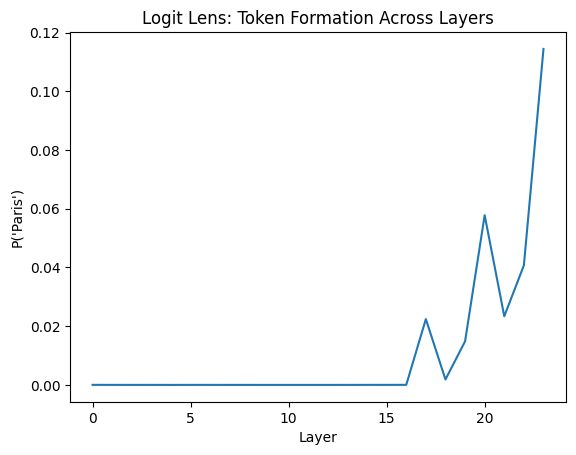

In [13]:
import torch
import matplotlib.pyplot as plt

tokens = model.to_tokens("The capital of France is")
logits, cache = model.run_with_cache(tokens)

target_token = model.to_single_token(" Paris")
probs = []

for layer in range(model.cfg.n_layers):
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    layer_logits = model.unembed(resid)
    prob = layer_logits.softmax(-1)[0, -1, target_token].item()
    probs.append(prob)

plt.plot(probs)
plt.xlabel("Layer")
plt.ylabel("P('Paris')")
plt.title("Logit Lens: Token Formation Across Layers")
plt.show()


In [14]:
topk = 10
for layer in [0, 6, 12, 18, 23]:
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    logits = model.unembed(resid)[0, -1]
    top_tokens = torch.topk(logits, topk)
    print(f"\nLayer {layer}")
    for score, idx in zip(top_tokens.values, top_tokens.indices):
        print(f"{model.to_string(idx):>10}  {score.item():.3f}")



Layer 0
      also  4.353
        ,&  4.264
       now  4.231
      Pant  3.951
        PI  3.896
 represented  3.876
     still  3.839
   neither  3.817
      omer  3.790
      magn  3.747

Layer 6
       now  7.421
    either  6.781
   playing  6.556
 therefore  6.439
      Emer  6.214
 represented  6.053
         a  5.921
      only  5.904
        an  5.799
       525  5.748

Layer 12
       not  7.710
       now  7.215
     never  6.910
    always  6.760
        an  6.661
         a  6.603
     often  6.540
      only  6.271
   neither  6.237
      also  6.155

Layer 18
         a  21.896
       the  20.306
         ,  19.142
        in  18.986
        an  18.815
       not  18.742
         f  18.285
   located  17.673
      also  17.669
        no  17.595

Layer 23
       the  22.989
         a  22.319
   located  22.130
     Paris  22.023
        in  20.723
       now  20.722
       one  20.619
       not  20.398
      home  20.284
        an  19.629


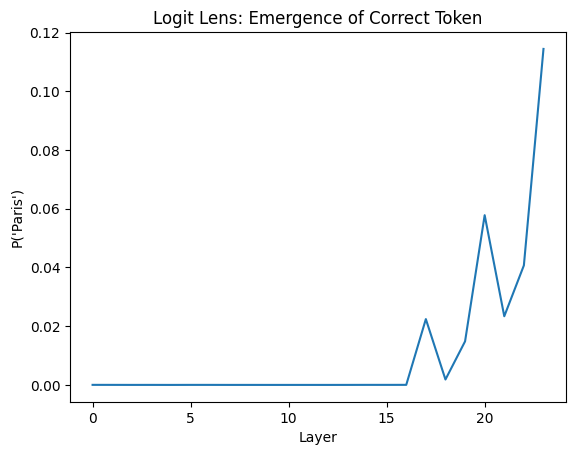

In [15]:
import matplotlib.pyplot as plt

tokens = model.to_tokens("The capital of France is")
logits, cache = model.run_with_cache(tokens)

target = model.to_single_token(" Paris")
probs = []

for layer in range(model.cfg.n_layers):
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    logits = model.unembed(resid)[0, -1]
    probs.append(logits.softmax(-1)[target].item())

plt.plot(probs)
plt.xlabel("Layer")
plt.ylabel("P('Paris')")
plt.title("Logit Lens: Emergence of Correct Token")
plt.show()


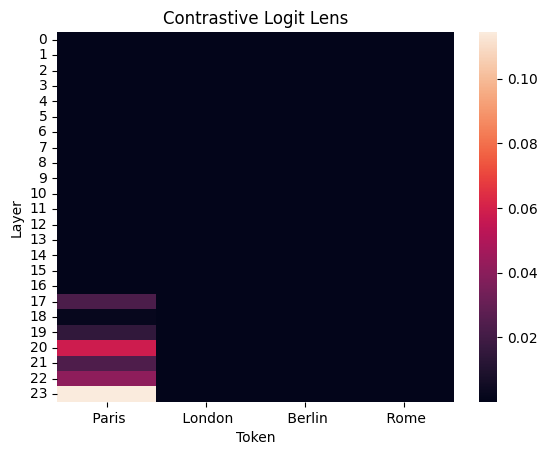

In [16]:
tokens_alt = [" Paris", " London", " Berlin", " Rome"]
ids = [model.to_single_token(t) for t in tokens_alt]

import numpy as np
heat = np.zeros((model.cfg.n_layers, len(ids)))

for layer in range(model.cfg.n_layers):
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    logits = model.unembed(resid)[0, -1].softmax(-1)
    heat[layer] = logits[ids].detach().cpu()

import seaborn as sns
sns.heatmap(heat, xticklabels=tokens_alt)
plt.xlabel("Token")
plt.ylabel("Layer")
plt.title("Contrastive Logit Lens")
plt.show()


In [17]:
import torch
import matplotlib.pyplot as plt

prompt = "The capital of France is"
tokens = model.to_tokens(prompt)
logits, cache = model.run_with_cache(tokens)


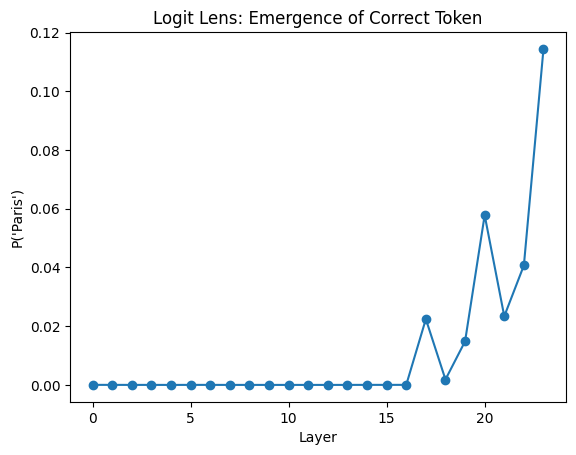

In [18]:
target = model.to_single_token(" Paris")
probs = []

for layer in range(model.cfg.n_layers):
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    logits_layer = model.unembed(resid)[0, -1]
    probs.append(logits_layer.softmax(-1)[target].item())

plt.plot(probs, marker="o")
plt.xlabel("Layer")
plt.ylabel("P('Paris')")
plt.title("Logit Lens: Emergence of Correct Token")
plt.show()


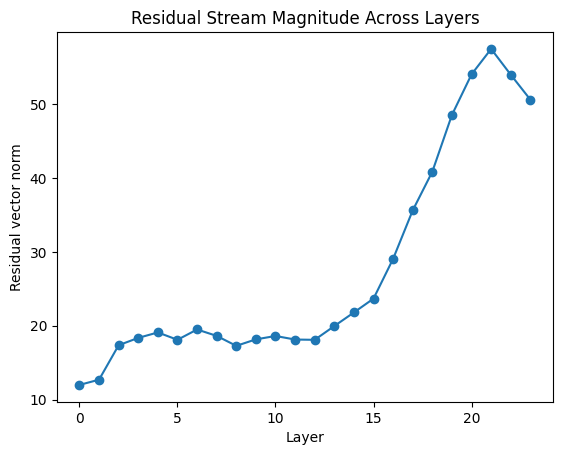

In [19]:
norms = []

for layer in range(model.cfg.n_layers):
    resid = cache[f"blocks.{layer}.hook_resid_post"]
    norms.append(resid.norm(dim=-1)[0, -1].item())

plt.plot(norms, marker="o")
plt.xlabel("Layer")
plt.ylabel("Residual vector norm")
plt.title("Residual Stream Magnitude Across Layers")
plt.show()


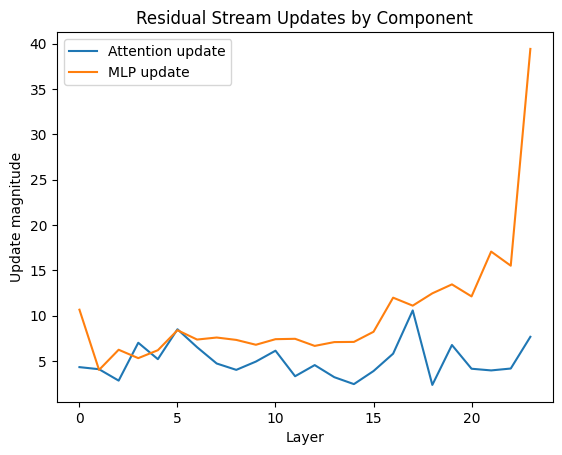

In [20]:
attn_delta = []
mlp_delta = []

for layer in range(model.cfg.n_layers):
    resid_pre = cache[f"blocks.{layer}.hook_resid_pre"]
    attn_out = cache[f"blocks.{layer}.hook_attn_out"]
    mlp_out = cache[f"blocks.{layer}.hook_mlp_out"]

    attn_delta.append(attn_out.norm(dim=-1)[0, -1].item())
    mlp_delta.append(mlp_out.norm(dim=-1)[0, -1].item())

import matplotlib.pyplot as plt
plt.plot(attn_delta, label="Attention update")
plt.plot(mlp_delta, label="MLP update")
plt.legend()
plt.xlabel("Layer")
plt.ylabel("Update magnitude")
plt.title("Residual Stream Updates by Component")
plt.show()


In [21]:
clean = model.to_tokens("The capital of France is Paris.")
corrupt = model.to_tokens("The capital of Germany is Paris.")


In [22]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

clean_prompt = "The capital of France is Paris."
corrupt_prompt = "The capital of Germany is Paris."

clean_tokens = model.to_tokens(clean_prompt)
corrupt_tokens = model.to_tokens(corrupt_prompt)

target = model.to_single_token(" Paris")


def metric(logits):
    return logits.softmax(-1)[0, -1, target].item()



PHASE 2: RESIDUAL STREAM DECOMPOSITION

Device: cpu

Loading Pythia-410M...

EXPERIMENT 1: LOGIT LENS ANALYSIS

 Analyzing: 'The capital of France is' 
Input tokens: ['The', 'Ġcapital', 'Ġof', 'ĠFrance', 'Ġis']

Layer-by-layer predictions:
  Embedding   : 'll' (prob: 0.031)
  Layer 0     : ' represented' (prob: 0.019)
  Layer 1     : 'PI' (prob: 0.033)
  Layer 2     : 'PI' (prob: 0.033)
  Layer 3     : ' either' (prob: 0.040)
  Layer 4     : ' either' (prob: 0.081)
  Layer 5     : ' either' (prob: 0.170)
  Layer 6     : ' either' (prob: 0.063)
  Layer 7     : ' therefore' (prob: 0.113)
  Layer 8     : ' therefore' (prob: 0.175)
  Layer 9     : ' only' (prob: 0.058)
  Layer 10    : ' nat' (prob: 0.044)
  Layer 11    : ' not' (prob: 0.041)
  Layer 12    : ' not' (prob: 0.079)
  Layer 13    : ' not' (prob: 0.184)
  Layer 14    : ' located' (prob: 0.108)
  Layer 15    : ' located' (prob: 0.381)
  Layer 16    : ' located' (prob: 0.313)
  Layer 17    : ' France' (prob: 0.501)
  Layer 18    :

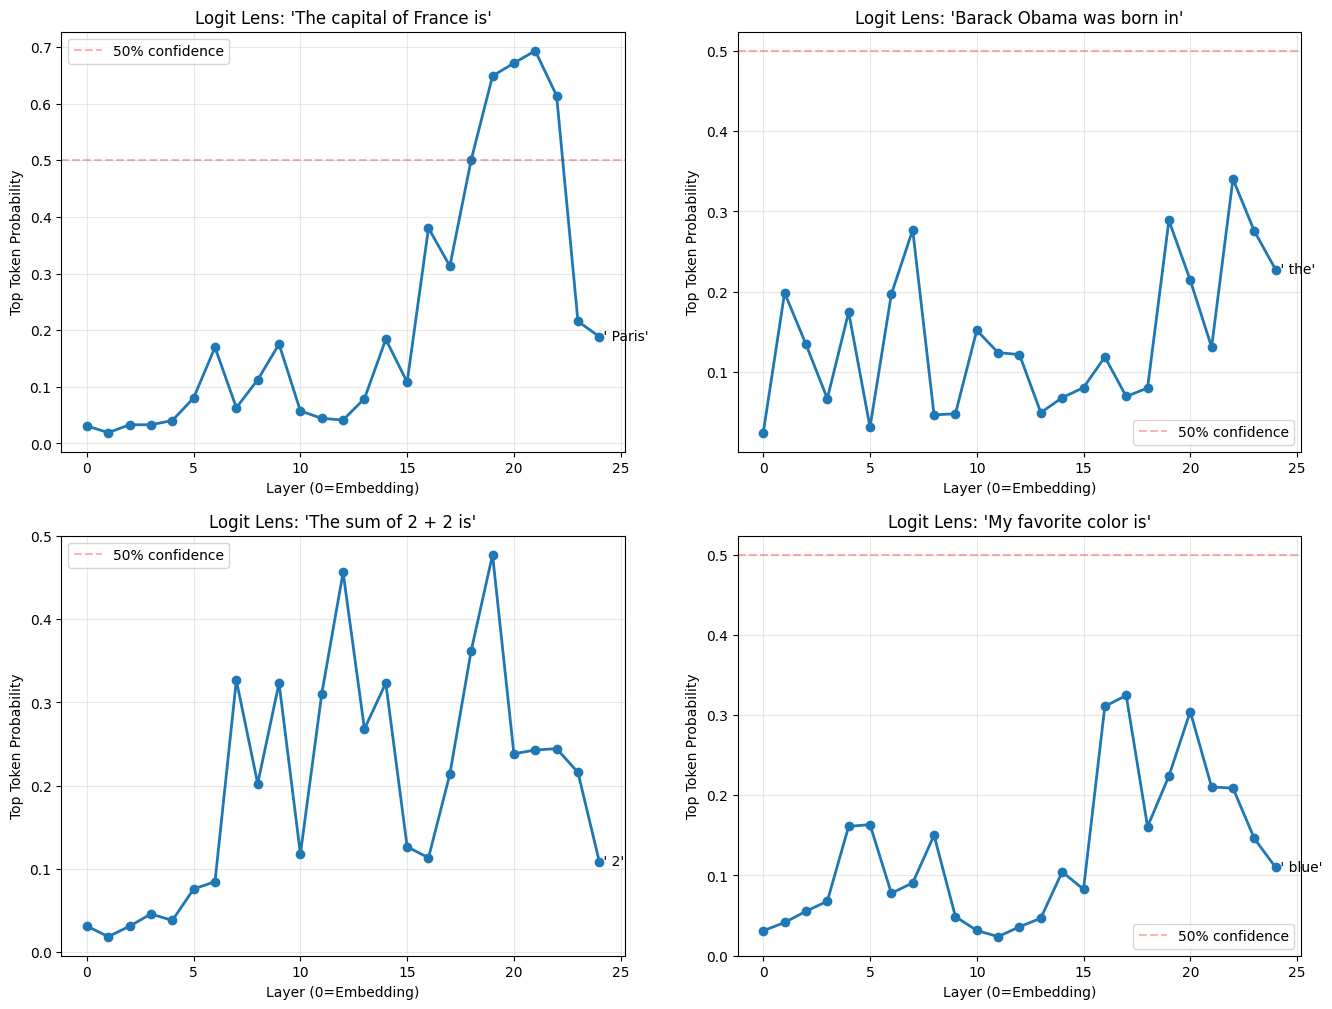

In [23]:
"""
PHASE 2: Residual Stream Decomposition (FIXED VERSION)
Goal: Identify where decisions form and which components dominate prediction

Prerequisites: Run pythia_410m_setup.py first
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from transformers import GPTNeoXForCausalLM, AutoTokenizer
from tqdm import tqdm
import json

print("=" * 80)
print("PHASE 2: RESIDUAL STREAM DECOMPOSITION")
print("=" * 80)


device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"\nDevice: {device}")

print("\nLoading Pythia-410M...")
model = GPTNeoXForCausalLM.from_pretrained(
    "EleutherAI/pythia-410m",
    torch_dtype=torch.float32,
    low_cpu_mem_usage=True
).to(device)
model.eval()

tokenizer = AutoTokenizer.from_pretrained("EleutherAI/pythia-410m")

# LOGIT LENS IMPLEMENTATION

class LogitLens:
    """
    Logit Lens: Project residual stream at each layer to vocabulary
    to see what the model "thinks" at each layer
    """

    def __init__(self, model):
        self.model = model
        self.ln_f = model.gpt_neox.final_layer_norm  # Final layer norm
        self.embed_out = model.embed_out  # Output projection to vocab

    def project_to_vocab(self, hidden_state):
        """
        Project hidden state to vocabulary logits

        hidden_state: [batch, seq_len, hidden_dim]
        returns: [batch, seq_len, vocab_size]
        """
        # Apply final layer norm
        normalized = self.ln_f(hidden_state)

        # Project to vocabulary
        logits = self.embed_out(normalized)

        return logits

    def analyze_text(self, text, target_position=-1):
        """
        Run logit lens analysis on text

        Args:
            text: input text
            target_position: which position to analyze (-1 = last token)

        Returns:
            Dictionary with layer-wise predictions and probabilities
        """
        # Tokenize
        inputs = tokenizer(text, return_tensors="pt").to(device)
        input_ids = inputs["input_ids"]

        # Get all hidden states
        with torch.no_grad():
            outputs = self.model(
                **inputs,
                output_hidden_states=True,
                return_dict=True
            )

        hidden_states = outputs.hidden_states  # Tuple of (num_layers + 1)

        results = {
            'input_text': text,
            'tokens': tokenizer.convert_ids_to_tokens(input_ids[0]),
            'target_position': target_position,
            'layer_predictions': [],
            'layer_probabilities': [],
            'top_tokens_per_layer': []
        }

        # Analyze each layer
        num_layers = len(hidden_states) - 1  # Exclude embedding layer

        for layer_idx in range(num_layers + 1):  # Include embedding (layer 0)
            hidden = hidden_states[layer_idx]  # [batch, seq, hidden]

            # Project to vocabulary
            logits = self.project_to_vocab(hidden)

            # Get logits for target position
            target_logits = logits[0, target_position, :]  # [vocab_size]

            # Get probabilities
            probs = torch.softmax(target_logits, dim=-1)

            # Top prediction
            top_token_id = torch.argmax(probs).item()
            top_token = tokenizer.decode([top_token_id])
            top_prob = probs[top_token_id].item()

            # Top 5 tokens - FIX: Added .detach()
            top5_probs, top5_ids = torch.topk(probs, k=5)
            top5_tokens = [tokenizer.decode([tid.item()]) for tid in top5_ids]

            results['layer_predictions'].append(top_token)
            results['layer_probabilities'].append(top_prob)
            results['top_tokens_per_layer'].append({
                'tokens': top5_tokens,
                'probs': top5_probs.detach().cpu().numpy().tolist()  # FIXED
            })

        return results

# RUN EXPERIMENTS

print("\n" + "=" * 80)
print("EXPERIMENT 1: LOGIT LENS ANALYSIS")
print("=" * 80)

logit_lens = LogitLens(model)

# Test examples
test_cases = [
    "The capital of France is",
    "Barack Obama was born in",
    "The sum of 2 + 2 is",
    "My favorite color is"
]

all_results = []

for test_text in test_cases:
    print(f"\n Analyzing: '{test_text}' ")

    result = logit_lens.analyze_text(test_text, target_position=-1)
    all_results.append(result)

    print(f"Input tokens: {result['tokens']}")
    print(f"\nLayer-by-layer predictions:")

    for layer_idx, (pred, prob) in enumerate(
        zip(result['layer_predictions'], result['layer_probabilities'])
    ):
        if layer_idx == 0:
            layer_name = "Embedding"
        else:
            layer_name = f"Layer {layer_idx-1}"

        print(f"  {layer_name:12s}: '{pred}' (prob: {prob:.3f})")

    # Check where prediction stabilizes
    predictions = result['layer_predictions']
    final_pred = predictions[-1]

    stabilization_layer = None
    for i in range(len(predictions)-1, -1, -1):
        if predictions[i] == final_pred:
            stabilization_layer = i
        else:
            break

    if stabilization_layer == 0:
        layer_name = "Embedding"
    else:
        layer_name = f"Layer {stabilization_layer-1}"

    print(f"\n   Prediction stabilizes at: {layer_name}")

# VISUALIZATIONS

print("\n--- Creating Visualizations ---")

import os
os.makedirs('phase2_results', exist_ok=True)

# Logit lens visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, result in enumerate(all_results[:4]):
    ax = axes[idx]

    layers = list(range(len(result['layer_predictions'])))
    probs = result['layer_probabilities']

    # Plot probability evolution
    ax.plot(layers, probs, marker='o', linewidth=2, markersize=6)
    ax.axhline(y=0.5, color='r', linestyle='--', alpha=0.3, label='50% confidence')

    ax.set_xlabel('Layer (0=Embedding)')
    ax.set_ylabel('Top Token Probability')
    ax.set_title(f"Logit Lens: '{result['input_text']}'")
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Add annotation for final prediction
    final_pred = result['layer_predictions'][-1]
    ax.text(len(layers)-1, probs[-1], f" '{final_pred}'",
            verticalalignment='center', fontsize=10)



In [25]:
from transformer_lens import HookedTransformer
import torch

# 1. Load model
model = HookedTransformer.from_pretrained("EleutherAI/pythia-410m")
model.eval()

# 2. Define prompts
clean_prompt   = "The capital of France is Paris."
corrupt_prompt = "The capital of Germany is Paris."

# 3. Tokenize
clean_tokens   = model.to_tokens(clean_prompt)
corrupt_tokens = model.to_tokens(corrupt_prompt)

# Safety check: shapes must match
assert clean_tokens.shape == corrupt_tokens.shape, (
    clean_tokens.shape, corrupt_tokens.shape
)

# 4. Run clean pass and cache activations
_, clean_cache = model.run_with_cache(clean_tokens)


Loaded pretrained model EleutherAI/pythia-410m into HookedTransformer


In [26]:
n_layers = model.cfg.n_layers
seq_len = clean_tokens.shape[1]
target_token = model.to_single_token(" Paris")

def metric(logits):
    return logits.softmax(-1)[0, -1, target_token].item()


patch_results = torch.zeros(seq_len, n_layers)

for layer in range(n_layers):
    for pos in range(seq_len):

        def patch_resid(x, hook, layer=layer, pos=pos):
            x[:, pos, :] = clean_cache[f"blocks.{layer}.hook_resid_pre"][:, pos, :]
            return x

        with model.hooks(fwd_hooks=[(f"blocks.{layer}.hook_resid_pre", patch_resid)]):
            logits = model(corrupt_tokens)
            patch_results[pos, layer] = metric(logits)


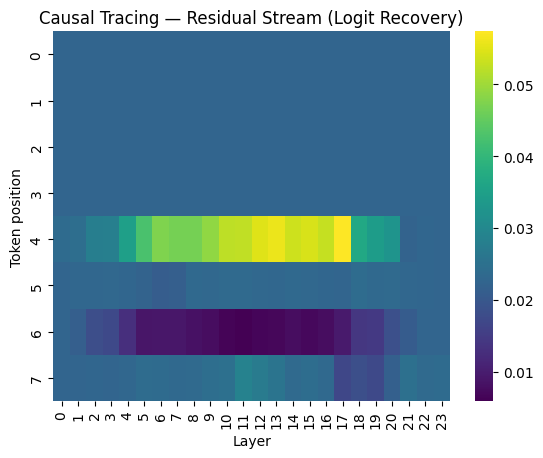

In [27]:
sns.heatmap(patch_results.cpu(), cmap="viridis")
plt.xlabel("Layer")
plt.ylabel("Token position")
plt.title("Causal Tracing — Residual Stream (Logit Recovery)")
plt.show()


In [28]:
clean_logits = model(clean_tokens)
corrupt_logits = model(corrupt_tokens)

clean_score = metric(clean_logits)
corrupt_score = metric(corrupt_logits)

print("clean:", clean_score, "corrupt:", corrupt_score, "gap:", clean_score - corrupt_score)


clean: 0.023745674639940262 corrupt: 0.022522492334246635 gap: 0.0012231823056936264


In [29]:
patch_results[pos, layer] = metric(logits) - corrupt_score


In [30]:
den = (clean_score - corrupt_score) + 1e-9
patch_results[pos, layer] = (metric(logits) - corrupt_score) / den


In [31]:
print(list(enumerate(model.to_str_tokens(clean_tokens[0]))))


[(0, '<|endoftext|>'), (1, 'The'), (2, ' capital'), (3, ' of'), (4, ' France'), (5, ' is'), (6, ' Paris'), (7, '.')]


In [32]:
layer_importance = patch_results.mean(dim=0)
pos_importance = patch_results.mean(dim=1)
attn_keys = [k for k in clean_cache.keys() if "attn.hook" in k]
print("\n".join(attn_keys[:50]))



blocks.0.attn.hook_q
blocks.0.attn.hook_k
blocks.0.attn.hook_v
blocks.0.attn.hook_rot_q
blocks.0.attn.hook_rot_k
blocks.0.attn.hook_attn_scores
blocks.0.attn.hook_pattern
blocks.0.attn.hook_z
blocks.1.attn.hook_q
blocks.1.attn.hook_k
blocks.1.attn.hook_v
blocks.1.attn.hook_rot_q
blocks.1.attn.hook_rot_k
blocks.1.attn.hook_attn_scores
blocks.1.attn.hook_pattern
blocks.1.attn.hook_z
blocks.2.attn.hook_q
blocks.2.attn.hook_k
blocks.2.attn.hook_v
blocks.2.attn.hook_rot_q
blocks.2.attn.hook_rot_k
blocks.2.attn.hook_attn_scores
blocks.2.attn.hook_pattern
blocks.2.attn.hook_z
blocks.3.attn.hook_q
blocks.3.attn.hook_k
blocks.3.attn.hook_v
blocks.3.attn.hook_rot_q
blocks.3.attn.hook_rot_k
blocks.3.attn.hook_attn_scores
blocks.3.attn.hook_pattern
blocks.3.attn.hook_z
blocks.4.attn.hook_q
blocks.4.attn.hook_k
blocks.4.attn.hook_v
blocks.4.attn.hook_rot_q
blocks.4.attn.hook_rot_k
blocks.4.attn.hook_attn_scores
blocks.4.attn.hook_pattern
blocks.4.attn.hook_z
blocks.5.attn.hook_q
blocks.5.attn.hook_

In [33]:
n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads

head_recovery = torch.zeros(n_layers, n_heads)
den = (clean_score - corrupt_score) + 1e-9

for layer in range(n_layers):
    act_name = f"blocks.{layer}.attn.hook_z"     # FIX
    clean_z  = clean_cache[act_name]             # [batch, pos, head, d_head]

    for head in range(n_heads):

        def patch_one_head(z, hook, head=head, clean_z=clean_z):
            z[:, :, head, :] = clean_z[:, :, head, :]
            return z

        with model.hooks(fwd_hooks=[(act_name, patch_one_head)]):
            patched_logits = model(corrupt_tokens)
            patched_score = metric(patched_logits)

        head_recovery[layer, head] = (patched_score - corrupt_score) / den


In [34]:
head_recovery_np = head_recovery.detach().cpu().numpy()


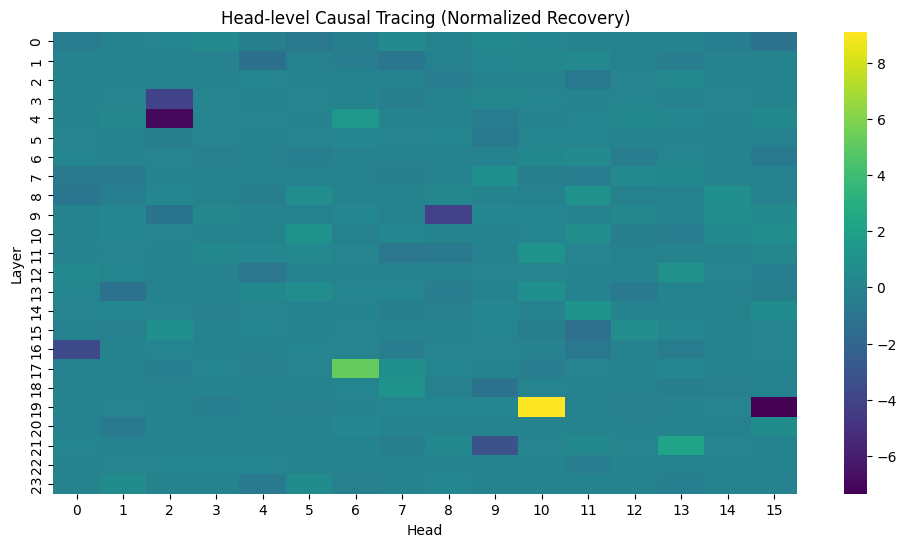

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.heatmap(head_recovery_np, cmap="viridis")
plt.xlabel("Head")
plt.ylabel("Layer")
plt.title("Head-level Causal Tracing (Normalized Recovery)")
plt.show()


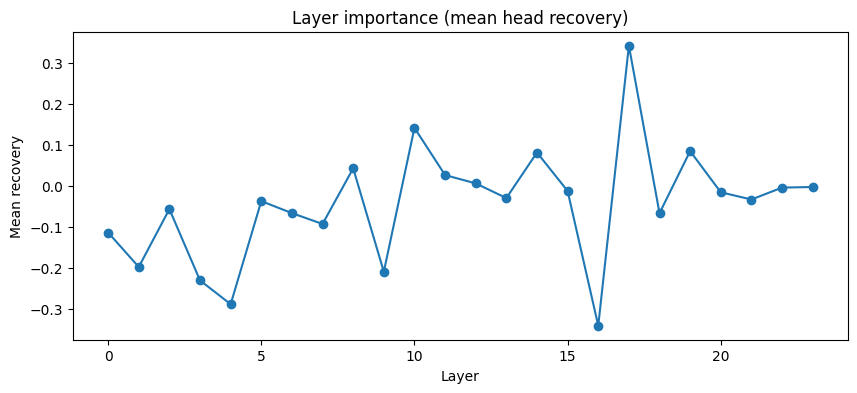

In [36]:
layer_imp = head_recovery_np.mean(axis=1)

plt.figure(figsize=(10,4))
plt.plot(layer_imp, marker="o")
plt.xlabel("Layer")
plt.ylabel("Mean recovery")
plt.title("Layer importance (mean head recovery)")
plt.show()


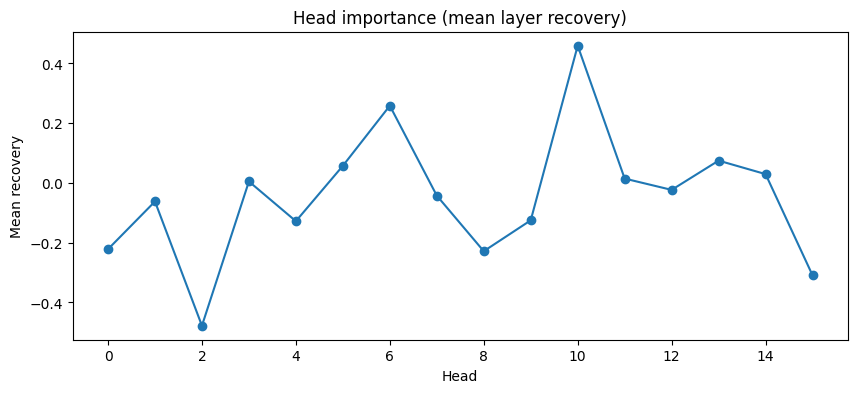

In [37]:
head_imp = head_recovery_np.mean(axis=0)

plt.figure(figsize=(10,4))
plt.plot(head_imp, marker="o")
plt.xlabel("Head")
plt.ylabel("Mean recovery")
plt.title("Head importance (mean layer recovery)")
plt.show()


In [38]:
import numpy as np

k = 10
flat_idx = np.argsort(head_recovery_np.ravel())[::-1][:k]
top_heads = [(idx // n_heads, idx % n_heads, head_recovery_np.ravel()[idx]) for idx in flat_idx]

top_heads


[(19, 10, 9.098434),
 (17, 6, 5.235764),
 (21, 13, 2.165662),
 (4, 6, 1.3847537),
 (14, 11, 1.1788656),
 (18, 7, 0.99791294),
 (10, 5, 0.9933309),
 (11, 10, 0.9711576),
 (8, 11, 0.93752235),
 (12, 13, 0.88033265)]

In [39]:
top_set = {(l, h) for (l, h, _) in top_heads}

def ablate_top_heads(z, hook):
    # z: [batch, pos, head, d_head]
    layer = hook.layer()
    for h in range(n_heads):
        if (layer, h) in top_set:
            z[:, :, h, :] = 0.0
    return z

hooks = [(f"blocks.{l}.attn.hook_z", ablate_top_heads) for (l, _, _) in top_heads]

with model.hooks(fwd_hooks=hooks):
    logits_clean_abl = model(clean_tokens)

print("clean baseline:", clean_score)
print("clean after ablation:", metric(logits_clean_abl))


clean baseline: 0.023745674639940262
clean after ablation: 0.00906912237405777


In [10]:
from transformer_lens import HookedTransformer
model = HookedTransformer.from_pretrained("EleutherAI/pythia-410m")
model.eval()

Loaded pretrained model EleutherAI/pythia-410m into HookedTransformer


HookedTransformer(
  (embed): Embed()
  (hook_embed): HookPoint()
  (blocks): ModuleList(
    (0-23): 24 x TransformerBlock(
      (ln1): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (ln2): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (attn): Attention(
        (hook_k): HookPoint()
        (hook_q): HookPoint()
        (hook_v): HookPoint()
        (hook_z): HookPoint()
        (hook_attn_scores): HookPoint()
        (hook_pattern): HookPoint()
        (hook_result): HookPoint()
        (hook_rot_k): HookPoint()
        (hook_rot_q): HookPoint()
      )
      (mlp): MLP(
        (hook_pre): HookPoint()
        (hook_post): HookPoint()
      )
      (hook_attn_in): HookPoint()
      (hook_q_input): HookPoint()
      (hook_k_input): HookPoint()
      (hook_v_input): HookPoint()
      (hook_mlp_in): HookPoint()
      (hook_attn_out): HookPoint()
      (hook_mlp_out): HookPoint(

In [11]:
facts = [
("France", "Paris"),
("Germany", "Berlin"),
("Italy", "Rome"),
("Spain", "Madrid"),
("Canada", "Ottawa"),
("Japan", "Tokyo"),
("China", "Beijing"),
("India", "New Delhi"),
("Brazil", "Brasilia"),
("Russia", "Moscow"),
("Syria", "Damascus")
]


In [12]:
import torch
import torch.nn.functional as F

def tokenize_answer(model, answer_text: str):
    # prepend a space so tokenization matches continuation
    return model.to_tokens(" " + answer_text, prepend_bos=False)[0]

def first_token_metric(model, answer_text: str):
    ans_toks = tokenize_answer(model, answer_text)
    target_id = ans_toks[0].item()

    def metric(logits):
        return logits.softmax(-1)[0, -1, target_id].item()
    return metric

def head_causal_trace(model, country, capital):
    clean_prompt   = f"The capital of {country} is {capital}."
    corrupt_prompt = f"The capital of {country} is Berlin."

    clean_tokens   = model.to_tokens(clean_prompt).to(device)
    corrupt_tokens = model.to_tokens(corrupt_prompt).to(device)

    # shared prefix
    seq_len = min(clean_tokens.shape[1], corrupt_tokens.shape[1])
    clean_tokens   = clean_tokens[:, :seq_len]
    corrupt_tokens = corrupt_tokens[:, :seq_len]

    _, clean_cache = model.run_with_cache(clean_tokens)

    # metric: probability of first token of the capital
    metric = first_token_metric(model, capital)

    clean_score   = metric(model(clean_tokens))
    corrupt_score = metric(model(corrupt_tokens))
    gap = clean_score - corrupt_score
    if gap <= 0:
        return None

    n_layers = model.cfg.n_layers
    n_heads  = model.cfg.n_heads
    head_recovery = torch.zeros(n_layers, n_heads)

    den = gap + 1e-9

    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"
        clean_z  = clean_cache[act_name]

        for head in range(n_heads):
            def patch_one_head(z, hook, head=head, clean_z=clean_z):
                z[:, :, head, :] = clean_z[:, :, head, :]
                return z

            with model.hooks(fwd_hooks=[(act_name, patch_one_head)]):
                patched_score = metric(model(corrupt_tokens))

            head_recovery[layer, head] = (patched_score - corrupt_score) / den

    return head_recovery


In [13]:
all_heatmaps = []

for country, capital in facts:
    result = head_causal_trace(model, country, capital)
    if result is not None:
        all_heatmaps.append(result)

all_heatmaps = torch.stack(all_heatmaps)
print("Collected heatmaps:", all_heatmaps.shape)


Collected heatmaps: torch.Size([7, 24, 16])


casual-importance structured pruning on the models

In [44]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformer_lens import HookedTransformer

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
model = HookedTransformer.from_pretrained("EleutherAI/pythia-410m")
model.eval()


Using device: cpu
Loaded pretrained model EleutherAI/pythia-410m into HookedTransformer


HookedTransformer(
  (embed): Embed()
  (hook_embed): HookPoint()
  (blocks): ModuleList(
    (0-23): 24 x TransformerBlock(
      (ln1): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (ln2): LayerNormPre(
        (hook_scale): HookPoint()
        (hook_normalized): HookPoint()
      )
      (attn): Attention(
        (hook_k): HookPoint()
        (hook_q): HookPoint()
        (hook_v): HookPoint()
        (hook_z): HookPoint()
        (hook_attn_scores): HookPoint()
        (hook_pattern): HookPoint()
        (hook_result): HookPoint()
        (hook_rot_k): HookPoint()
        (hook_rot_q): HookPoint()
      )
      (mlp): MLP(
        (hook_pre): HookPoint()
        (hook_post): HookPoint()
      )
      (hook_attn_in): HookPoint()
      (hook_q_input): HookPoint()
      (hook_k_input): HookPoint()
      (hook_v_input): HookPoint()
      (hook_mlp_in): HookPoint()
      (hook_attn_out): HookPoint()
      (hook_mlp_out): HookPoint(

In [18]:
import torch
import torch.nn.functional as F

def compute_perplexity(model, text, stride=512):
    tokens = model.to_tokens(text, prepend_bos=True).to(device)  # [1, T]
    T = tokens.shape[1]

    total_nll = 0.0
    total_tokens = 0

    for start in range(0, T - 1, stride):
        end = min(start + stride, T)

        input_ids = tokens[:, start:end]          # [1, L]
        logits = model(input_ids)                 # [1, L, V]

        # targets are next tokens inside the same window
        target_ids = tokens[:, start+1:end]       # [1, L-1]

        # align logits to predict target_ids
        logits = logits[:, :-1, :]                # [1, L-1, V]

        loss = F.cross_entropy(
            logits.reshape(-1, logits.size(-1)),
            target_ids.reshape(-1),
            reduction="sum"
        )

        total_nll += loss.item()
        total_tokens += target_ids.numel()

    avg_nll = total_nll / total_tokens
    ppl = float(torch.exp(torch.tensor(avg_nll)))
    return ppl


In [46]:
sample_text = """
France is a country in Europe. Paris is its capital city.
Germany is another European country. Berlin is its capital.
Italy has Rome as its capital.
"""

baseline_ppl = compute_perplexity(model, sample_text)
print("Baseline Perplexity:", baseline_ppl)


Baseline Perplexity: 10.6354341506958


Mean head recovery shape: torch.Size([24, 16])


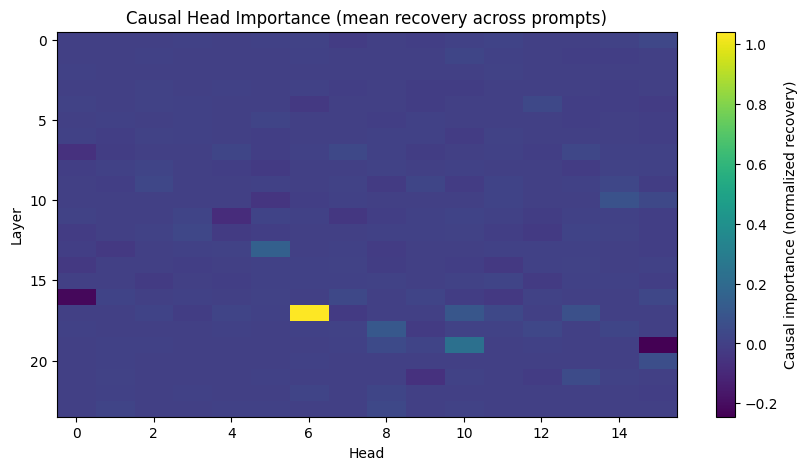

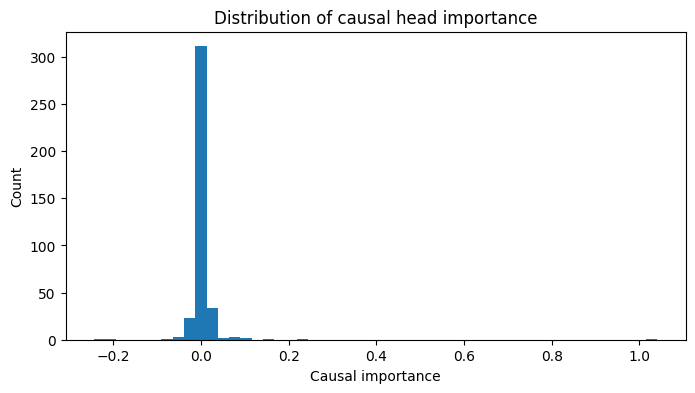

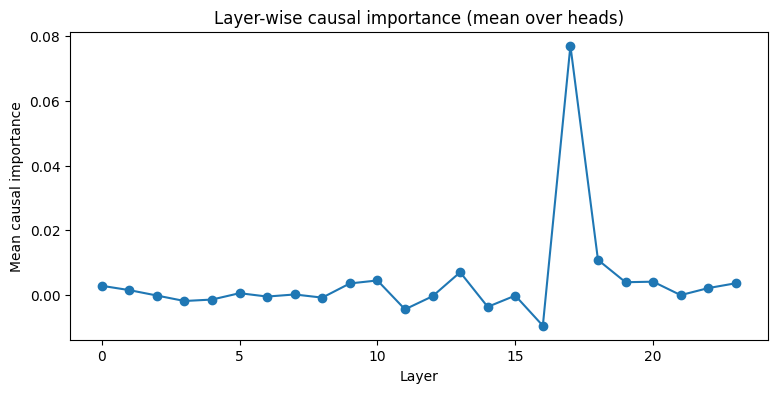

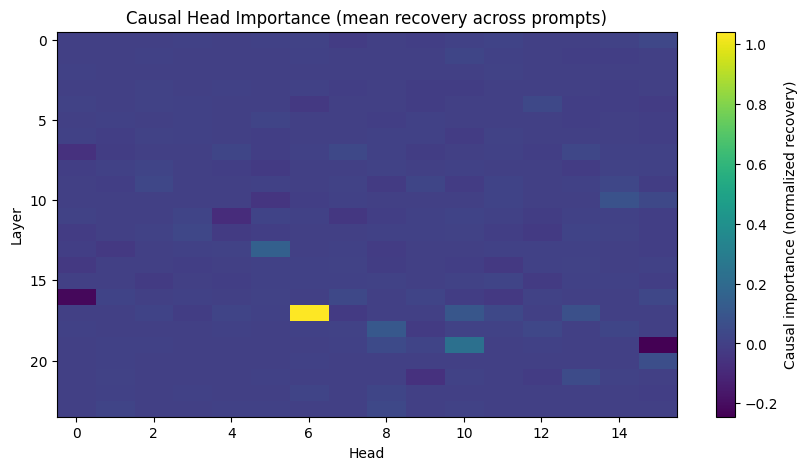

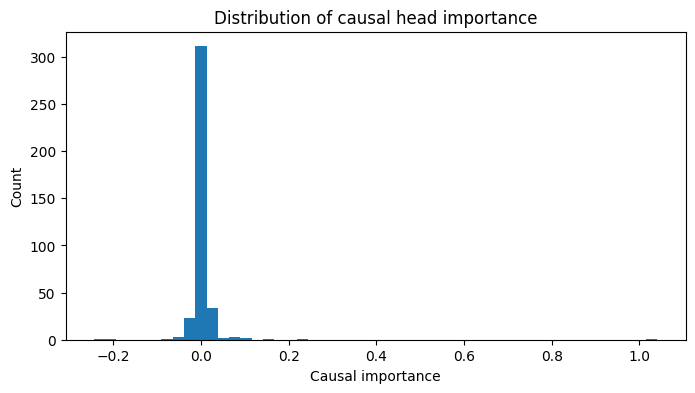

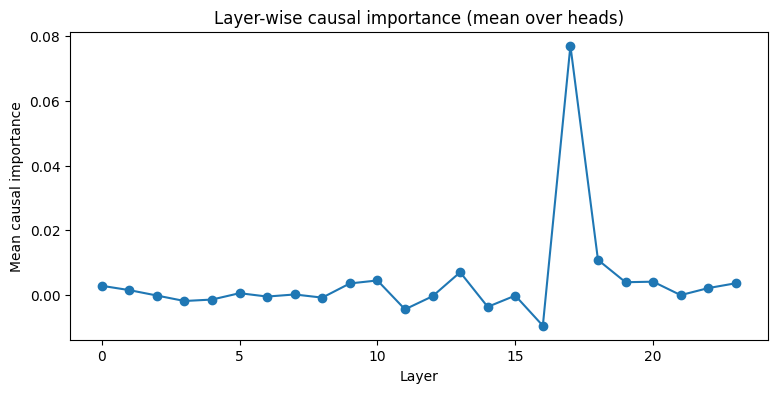

In [47]:
import numpy as np
import matplotlib.pyplot as plt
all_heatmaps
mean_hr = all_heatmaps.mean(dim=0)   # shape: [layers, heads]
print("Mean head recovery shape:", mean_hr.shape)

mean_hr_t = torch.tensor(mean_hr) if not torch.is_tensor(mean_hr) else mean_hr
mean_hr_np = mean_hr_t.detach().cpu().numpy()

# Heatmap of head importance (Layer x Head)
plt.figure(figsize=(10,5))
plt.imshow(mean_hr_np, aspect="auto")
plt.colorbar(label="Causal importance (normalized recovery)")
plt.xlabel("Head")
plt.ylabel("Layer")
plt.title("Causal Head Importance (mean recovery across prompts)")
plt.show()

# Distribution
plt.figure(figsize=(8,4))
plt.hist(mean_hr_np.flatten(), bins=50)
plt.xlabel("Causal importance")
plt.ylabel("Count")
plt.title("Distribution of causal head importance")
plt.show()

# Layer importance curve
layer_imp = mean_hr_np.mean(axis=1)
plt.figure(figsize=(9,4))
plt.plot(layer_imp, marker="o")
plt.xlabel("Layer")
plt.ylabel("Mean causal importance")
plt.title("Layer-wise causal importance (mean over heads)")
plt.show()

import matplotlib.pyplot as plt

mean_hr_t = torch.tensor(mean_hr) if not torch.is_tensor(mean_hr) else mean_hr
mean_hr_np = mean_hr_t.detach().cpu().numpy()

# Heatmap of head importance (Layer x Head)
plt.figure(figsize=(10,5))
plt.imshow(mean_hr_np, aspect="auto")
plt.colorbar(label="Causal importance (normalized recovery)")
plt.xlabel("Head")
plt.ylabel("Layer")
plt.title("Causal Head Importance (mean recovery across prompts)")
plt.show()

# Distribution
plt.figure(figsize=(8,4))
plt.hist(mean_hr_np.flatten(), bins=50)
plt.xlabel("Causal importance")
plt.ylabel("Count")
plt.title("Distribution of causal head importance")
plt.show()

# Layer importance curve
layer_imp = mean_hr_np.mean(axis=1)
plt.figure(figsize=(9,4))
plt.plot(layer_imp, marker="o")
plt.xlabel("Layer")
plt.ylabel("Mean causal importance")
plt.title("Layer-wise causal importance (mean over heads)")
plt.show()


In [48]:
n_layers = mean_hr.shape[0]
n_heads  = mean_hr.shape[1]

flat_scores = mean_hr.flatten()
sorted_idx = torch.argsort(flat_scores)  # ascending


In [49]:
def build_pruning_hooks(prune_set):
    hooks = []

    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"

        def make_hook(layer):
            def hook_fn(z, hook):
                for h in range(n_heads):
                    if (layer, h) in prune_set:
                        z[:, :, h, :] = 0.0
                return z
            return hook_fn

        hooks.append((act_name, make_hook(layer)))

    return hooks


In [50]:
import torch

def build_pruning_hooks(prune_set, n_layers, n_heads, device):
    """
    Zero selected heads in blocks.{layer}.attn.hook_z using a vectorized mask.
    z shape: [batch, pos, head, d_head]
    """
    mask = torch.ones(n_layers, n_heads, device=device)

    for (layer, head) in prune_set:
        mask[layer, head] = 0.0

    hooks = []
    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"

        def make_hook(layer):
            def hook_fn(z, hook):
                return z * mask[layer][None, None, :, None]
            return hook_fn

        hooks.append((act_name, make_hook(layer)))

    return hooks


In [51]:
test_prune_set = {(0,0), (0,1)}
hooks = build_pruning_hooks(test_prune_set, n_layers, n_heads, device)

# Run one forward pass and ensure it doesn't crash
with model.hooks(fwd_hooks=hooks):
    _ = model(model.to_tokens("Hello world").to(device))
print("Hook test OK")


Hook test OK


In [52]:
import numpy as np
import random
import matplotlib.pyplot as plt
import torch
def head_causal_trace(model, country, capital, corrupt_country="Germany"):
    clean_prompt   = f"The capital of {country} is {capital}."
    corrupt_prompt = f"The capital of {corrupt_country} is {capital}."

    clean_tokens   = model.to_tokens(clean_prompt, prepend_bos=True).to(device)
    corrupt_tokens = model.to_tokens(corrupt_prompt, prepend_bos=True).to(device)

    # align length
    seq_len = min(clean_tokens.shape[1], corrupt_tokens.shape[1])
    clean_tokens   = clean_tokens[:, :seq_len]
    corrupt_tokens = corrupt_tokens[:, :seq_len]

    _, clean_cache = model.run_with_cache(clean_tokens)

    metric = first_token_metric(model, capital)

    clean_score   = metric(model(clean_tokens))
    corrupt_score = metric(model(corrupt_tokens))
    gap = clean_score - corrupt_score

    print(f"[{country}->{capital}] clean={clean_score:.4f} corrupt={corrupt_score:.4f} gap={gap:.4f}")

    if gap <= 1e-6:
        return None

    n_layers = model.cfg.n_layers
    n_heads  = model.cfg.n_heads
    head_recovery = torch.zeros(n_layers, n_heads, device=device)

    den = gap + 1e-9

    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"
        clean_z  = clean_cache[act_name]

        for head in range(n_heads):
            def patch_one_head(z, hook, head=head, clean_z=clean_z):
                z[:, :, head, :] = clean_z[:, :, head, :]
                return z

            with model.hooks(fwd_hooks=[(act_name, patch_one_head)]):
                patched_score = metric(model(corrupt_tokens))

            head_recovery[layer, head] = (patched_score - corrupt_score) / den

    return head_recovery.detach().cpu()



In [53]:
facts_small = [("France", "Paris"), ("Italy", "Rome")]


In [54]:
all_heatmaps = []
for country, capital in facts_small:
    hr = head_causal_trace(model, country, capital, corrupt_country="Germany")
    if hr is not None:
        all_heatmaps.append(hr)

print("Collected:", len(all_heatmaps))
mean_hr = torch.stack(all_heatmaps).mean(dim=0)
print("mean_hr shape:", mean_hr.shape)


[France->Paris] clean=0.0237 corrupt=0.0225 gap=0.0012
[Italy->Rome] clean=0.0146 corrupt=0.0233 gap=-0.0087
Collected: 1
mean_hr shape: torch.Size([24, 16])


In [55]:
def gap_only(model, country, capital, corrupt_country="Germany"):
    clean_prompt   = f"The capital of {country} is {capital}."
    corrupt_prompt = f"The capital of {corrupt_country} is {capital}."

    clean_tokens   = model.to_tokens(clean_prompt, prepend_bos=True).to(device)
    corrupt_tokens = model.to_tokens(corrupt_prompt, prepend_bos=True).to(device)
    seq_len = min(clean_tokens.shape[1], corrupt_tokens.shape[1])
    clean_tokens, corrupt_tokens = clean_tokens[:, :seq_len], corrupt_tokens[:, :seq_len]

    metric = first_token_metric(model, capital)
    clean_score   = metric(model(clean_tokens))
    corrupt_score = metric(model(corrupt_tokens))
    return clean_score, corrupt_score, clean_score - corrupt_score

facts_try = [
    ("France","Paris"),
    ("Spain","Madrid"),
    ("Japan","Tokyo"),
    ("China","Beijing"),
    ("Canada","Ottawa"),
    ("Russia","Moscow"),
    ("Brazil","Brasilia"),
    ("India","New Delhi"),
    ('Syria', "Damascus")
]

good = []
for ctry, cap in facts_try:
    clean_s, corr_s, gap = gap_only(model, ctry, cap, corrupt_country="Germany")
    print(f"{ctry}->{cap}: clean={clean_s:.4f} corrupt={corr_s:.4f} gap={gap:.4f}")
    if gap > 0.0005:
        good.append((ctry, cap))

print("Good facts:", good)


France->Paris: clean=0.0237 corrupt=0.0225 gap=0.0012
Spain->Madrid: clean=0.0322 corrupt=0.0147 gap=0.0175
Japan->Tokyo: clean=0.0263 corrupt=0.0210 gap=0.0053
China->Beijing: clean=0.0234 corrupt=0.0156 gap=0.0078
Canada->Ottawa: clean=0.0337 corrupt=0.0477 gap=-0.0140
Russia->Moscow: clean=0.0355 corrupt=0.0181 gap=0.0173
Brazil->Brasilia: clean=0.0059 corrupt=0.0269 gap=-0.0210
India->New Delhi: clean=0.0266 corrupt=0.0245 gap=0.0021
Syria->Damascus: clean=0.0108 corrupt=0.0048 gap=0.0060
Good facts: [('France', 'Paris'), ('Spain', 'Madrid'), ('Japan', 'Tokyo'), ('China', 'Beijing'), ('Russia', 'Moscow'), ('India', 'New Delhi'), ('Syria', 'Damascus')]


In [56]:
facts_small = good[:3]  # start with 3

all_heatmaps = []
for country, capital in facts_small:
    hr = head_causal_trace(model, country, capital, corrupt_country="Germany")
    if hr is not None:
        all_heatmaps.append(hr)

mean_hr = torch.stack(all_heatmaps).mean(dim=0)
print("Used examples:", len(all_heatmaps))
print("mean_hr:", mean_hr.shape)


[France->Paris] clean=0.0237 corrupt=0.0225 gap=0.0012
[Spain->Madrid] clean=0.0322 corrupt=0.0147 gap=0.0175
[Japan->Tokyo] clean=0.0263 corrupt=0.0210 gap=0.0053
Used examples: 3
mean_hr: torch.Size([24, 16])


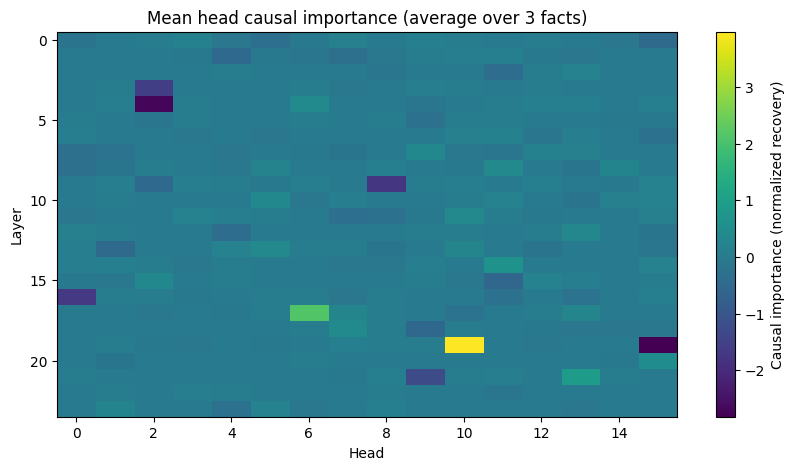

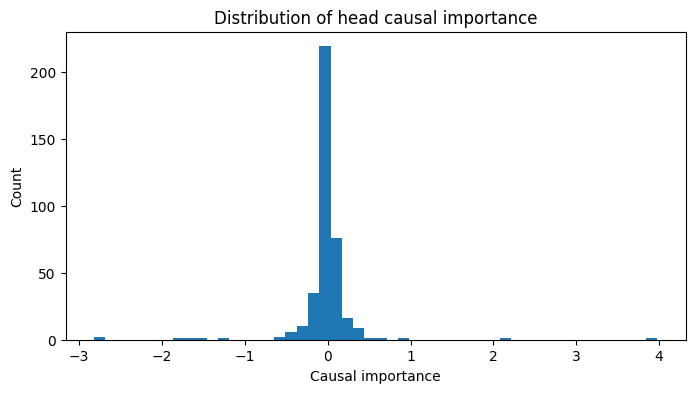

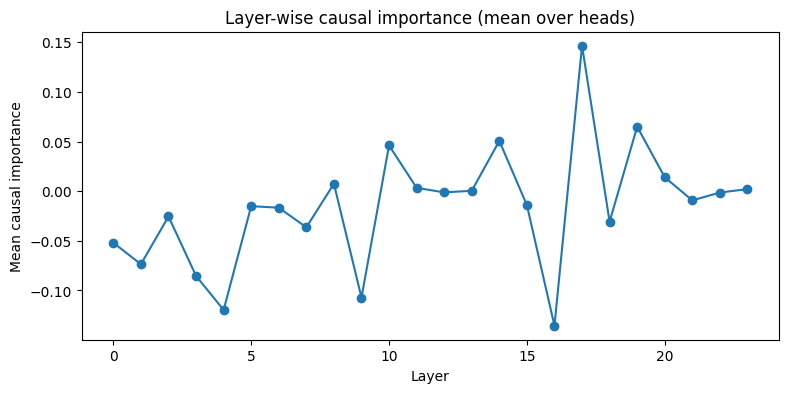

In [57]:
import matplotlib.pyplot as plt
import numpy as np

mean_hr_np = mean_hr.detach().cpu().numpy()

plt.figure(figsize=(10,5))
plt.imshow(mean_hr_np, aspect="auto")
plt.colorbar(label="Causal importance (normalized recovery)")
plt.xlabel("Head")
plt.ylabel("Layer")
plt.title("Mean head causal importance (average over 3 facts)")
plt.show()

plt.figure(figsize=(8,4))
plt.hist(mean_hr_np.flatten(), bins=50)
plt.xlabel("Causal importance")
plt.ylabel("Count")
plt.title("Distribution of head causal importance")
plt.show()

layer_imp = mean_hr_np.mean(axis=1)
plt.figure(figsize=(9,4))
plt.plot(layer_imp, marker="o")
plt.xlabel("Layer")
plt.ylabel("Mean causal importance")
plt.title("Layer-wise causal importance (mean over heads)")
plt.show()


In [58]:
import random

n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads

all_heads = [(l, h) for l in range(n_layers) for h in range(n_heads)]
total_heads = len(all_heads)

flat_scores = mean_hr.flatten()
sorted_idx = torch.argsort(flat_scores)  # least important first

ratios = [0.0, 0.25, 0.5, 0.75]
ppl_causal = []
ppl_random = []

random_trials = 3  # average random baseline

for ratio in ratios:
    print(f"\n=== Pruning ratio: {ratio:.0%} ===")

    if ratio == 0.0:
        ppl_causal.append(baseline_ppl)
        ppl_random.append(baseline_ppl)
        print("No pruning. PPL:", baseline_ppl)
        continue

    k = int(ratio * total_heads)

    # Causal pruning: prune bottom-k heads by mean_hr
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    prune_set = {(i // n_heads, i % n_heads) for i in prune_idx}
    hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)

    with model.hooks(fwd_hooks=hooks):
        ppl = compute_perplexity(model, sample_text, stride=256)
    ppl_causal.append(ppl)
    print("Causal-pruned PPL:", ppl)

    # Random pruning: average over trials
    trial_ppls = []
    for _ in range(random_trials):
        rand_set = set(random.sample(all_heads, k))
        hooks_r = build_pruning_hooks(rand_set, n_layers, n_heads, device)
        with model.hooks(fwd_hooks=hooks_r):
            trial_ppls.append(compute_perplexity(model, sample_text, stride=256))

    ppl_r = float(np.mean(trial_ppls))
    ppl_random.append(ppl_r)
    print(f"Random-pruned PPL (avg {random_trials}):", ppl_r)

print("\nBaseline PPL:", baseline_ppl)
print("Ratios:", ratios)
print("Causal PPL:", ppl_causal)
print("Random PPL:", ppl_random)
#in 25% Heads important for factual recall are not necessarily heads important for general language modeling (that's what the results say)
#in 50, Once pruning becomes significant, removing causally unimportant heads preserves global performance better than random removal.
#75 Under extreme sparsification, mechanism-aware pruning degrades much more gracefully.


=== Pruning ratio: 0% ===
No pruning. PPL: 10.6354341506958

=== Pruning ratio: 25% ===
Causal-pruned PPL: 28.419952392578125
Random-pruned PPL (avg 3): 16.691055615743

=== Pruning ratio: 50% ===
Causal-pruned PPL: 34.74674606323242
Random-pruned PPL (avg 3): 43.07616869608561

=== Pruning ratio: 75% ===
Causal-pruned PPL: 200.22731018066406
Random-pruned PPL (avg 3): 347.27190653483075

Baseline PPL: 10.6354341506958
Ratios: [0.0, 0.25, 0.5, 0.75]
Causal PPL: [10.6354341506958, 28.419952392578125, 34.74674606323242, 200.22731018066406]
Random PPL: [10.6354341506958, 16.691055615743, 43.07616869608561, 347.27190653483075]


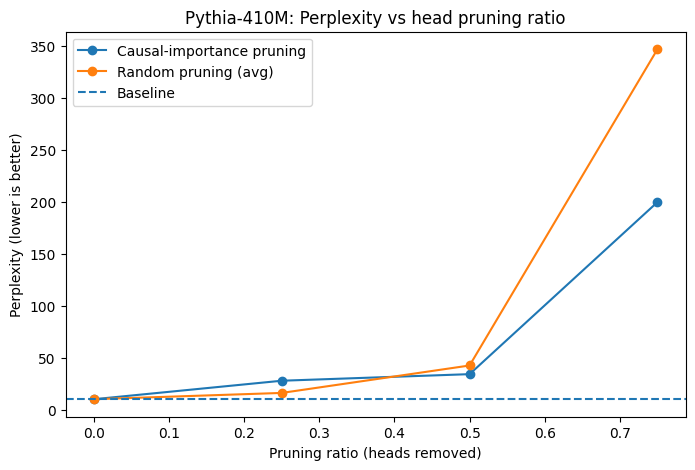

In [59]:
plt.figure(figsize=(8,5))
plt.plot(ratios, ppl_causal, marker="o", label="Causal-importance pruning")
plt.plot(ratios, ppl_random, marker="o", label="Random pruning (avg)")
plt.axhline(baseline_ppl, linestyle="--", label="Baseline")
plt.xlabel("Pruning ratio (heads removed)")
plt.ylabel("Perplexity (lower is better)")
plt.title("Pythia-410M: Perplexity vs head pruning ratio")
plt.legend()
plt.show()


In [60]:
least10 = sorted_idx[:10].detach().cpu().tolist()
print("Bottom 10 heads (pruned first):")
for i in least10:
    l, h = i // n_heads, i % n_heads
    print(f"Layer {l}, Head {h}, score={flat_scores[i].item():.4f}")


Bottom 10 heads (pruned first):
Layer 19, Head 15, score=-2.8216
Layer 4, Head 2, score=-2.7147
Layer 9, Head 8, score=-1.7516
Layer 16, Head 0, score=-1.6899
Layer 3, Head 2, score=-1.5598
Layer 21, Head 9, score=-1.2362
Layer 15, Head 11, score=-0.5772
Layer 18, Head 9, score=-0.5625
Layer 9, Head 2, score=-0.4935
Layer 1, Head 4, score=-0.4841


In [24]:
import numpy as np, random, torch

n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads
all_heads = [(l, h) for l in range(n_layers) for h in range(n_heads)]
total_heads = len(all_heads)

flat_scores = mean_hr.flatten()
sorted_idx = torch.argsort(flat_scores)  # least important first

ratios = [0.25, 0.5, 0.75]

def causal_prune_set(ratio):
    k = int(ratio * total_heads)
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    return {(i // n_heads, i % n_heads) for i in prune_idx}

def random_prune_set(ratio, seed):
    rng = random.Random(seed)
    k = int(ratio * total_heads)
    return set(rng.sample(all_heads, k))

In [20]:
texts = [("""
France is a country in Western Europe. It has a long history and diverse regions.
Paris is the capital city and is known for culture, science, and tourism.
""" * 50),

("""
Transformers are neural networks that use self-attention to process sequences.
They are trained with next-token prediction and scale well with data and compute.
""" * 50)]

def ppl_with_hooks(text, hooks=None):
    if hooks is None:
        return compute_perplexity(model, text, stride=256)
    with model.hooks(fwd_hooks=hooks):
        return compute_perplexity(model, text, stride=256)

baseline_ppls = [ppl_with_hooks(t) for t in texts]
baseline_mean = float(np.mean(baseline_ppls))
print("Baseline PPLs:", baseline_ppls)
print("Baseline mean:", baseline_mean)


Baseline PPLs: [1.574119210243225, 1.879886507987976]
Baseline mean: 1.7270028591156006


In [63]:
facts_test = [
    ("France","Paris"),
    ("Spain","Madrid"),
    ("Japan","Tokyo"),
    ("China","Beijing"),
    ("Russia","Moscow"),
    ("Canada","Ottawa"),
]

def factual_score(model, facts, hooks=None):
    scores = []
    for country, capital in facts:
        prompt = f"The capital of {country} is"
        toks = model.to_tokens(prompt, prepend_bos=True).to(device)

        metric = first_token_metric(model, capital)

        if hooks is None:
            s = metric(model(toks))
        else:
            with model.hooks(fwd_hooks=hooks):
                s = metric(model(toks))
        scores.append(s)

    return float(np.mean(scores)), scores


In [64]:
import matplotlib.pyplot as plt

random_trials = 5
results = {}

for ratio in ratios:
    # hooks for causal pruning
    cset = causal_prune_set(ratio)
    chooks = build_pruning_hooks(cset, n_layers, n_heads, device)

    # evaluate causal
    causal_ppls = [ppl_with_hooks(t, chooks) for t in texts]
    causal_ppl_mean = float(np.mean(causal_ppls))
    causal_fact_mean, _ = factual_score(model, facts_test, chooks)

    # evaluate random (average)
    rand_ppl_means = []
    rand_fact_means = []

    for seed in range(random_trials):
        rset = random_prune_set(ratio, seed=seed)
        rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)

        rppls = [ppl_with_hooks(t, rhooks) for t in texts]
        rand_ppl_means.append(float(np.mean(rppls)))

        rfact_mean, _ = factual_score(model, facts_test, rhooks)
        rand_fact_means.append(rfact_mean)

    results[ratio] = {
        "causal_ppl_mean": causal_ppl_mean,
        "random_ppl_mean": float(np.mean(rand_ppl_means)),
        "random_ppl_std": float(np.std(rand_ppl_means)),
        "causal_fact_mean": causal_fact_mean,
        "random_fact_mean": float(np.mean(rand_fact_means)),
        "random_fact_std": float(np.std(rand_fact_means)),
    }

    print("\nRatio:", ratio)
    print(results[ratio])



Ratio: 0.25
{'causal_ppl_mean': 3.636392831802368, 'random_ppl_mean': 3.422571587562561, 'random_ppl_std': 1.15973297543521, 'causal_fact_mean': 0.003348425729200244, 'random_fact_mean': 0.04392599316197447, 'random_fact_std': 0.05228281605578551}

Ratio: 0.5
{'causal_ppl_mean': 72.37338447570801, 'random_ppl_mean': 39.156859970092775, 'random_ppl_std': 29.092141255937292, 'causal_fact_mean': 0.0008774598391028121, 'random_fact_mean': 0.005843857157742605, 'random_fact_std': 0.00647083796524326}

Ratio: 0.75
{'causal_ppl_mean': 247.69523239135742, 'random_ppl_mean': 242.72176513671874, 'random_ppl_std': 61.069196831884845, 'causal_fact_mean': 2.434906582493568e-05, 'random_fact_mean': 1.5617258947031586e-05, 'random_fact_std': 1.1438698631908772e-05}


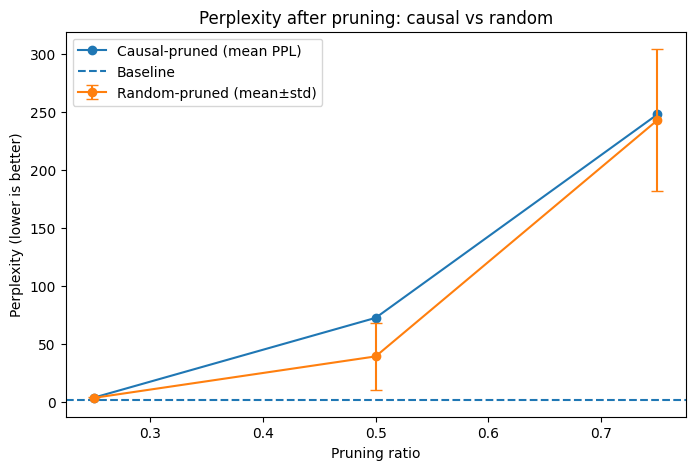

In [65]:
x = ratios
causal_y = [results[r]["causal_ppl_mean"] for r in x]
rand_y   = [results[r]["random_ppl_mean"] for r in x]
rand_e   = [results[r]["random_ppl_std"] for r in x]

plt.figure(figsize=(8,5))
plt.plot(x, causal_y, marker="o", label="Causal-pruned (mean PPL)")
plt.errorbar(x, rand_y, yerr=rand_e, marker="o", capsize=4, label="Random-pruned (mean±std)")
plt.axhline(baseline_mean, linestyle="--", label="Baseline")
plt.xlabel("Pruning ratio")
plt.ylabel("Perplexity (lower is better)")
plt.title("Perplexity after pruning: causal vs random")
plt.legend()
plt.show()


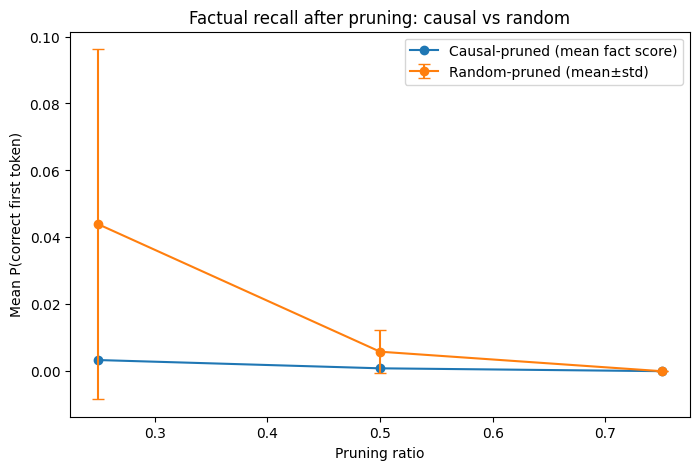

In [66]:
causal_f = [results[r]["causal_fact_mean"] for r in x]
rand_f   = [results[r]["random_fact_mean"] for r in x]
rand_fe  = [results[r]["random_fact_std"] for r in x]

plt.figure(figsize=(8,5))
plt.plot(x, causal_f, marker="o", label="Causal-pruned (mean fact score)")
plt.errorbar(x, rand_f, yerr=rand_fe, marker="o", capsize=4, label="Random-pruned (mean±std)")
plt.xlabel("Pruning ratio")
plt.ylabel("Mean P(correct first token)")
plt.title("Factual recall after pruning: causal vs random")
plt.legend()
plt.show()


In [14]:
n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads


In [15]:
def causal_prune_set(ratio):
    flat = mean_hr.flatten()
    sorted_idx = torch.argsort(flat)  # least important first
    k = int(ratio * flat.numel())
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    return {(idx // n_heads, idx % n_heads) for idx in prune_idx}
print(df.shape)
print(df.head())



(24, 5)
   Layer  Attention      MLP  LayerNorm     Total
0      0    4198400  8393728       4096  12596224
1      1    4198400  8393728       4096  12596224
2      2    4198400  8393728       4096  12596224
3      3    4198400  8393728       4096  12596224
4      4    4198400  8393728       4096  12596224


In [16]:
facts_small = [
    ("France", "Paris"),
    ("Spain", "Madrid"),
    ("Japan", "Tokyo"),
]
import torch, gc

all_heatmaps = []

for country, capital in facts_small:
    print("Tracing:", country, capital)
    hr = head_causal_trace(model, country, capital)   # should return [24, 16] tensor
    if hr is not None:
        all_heatmaps.append(hr.detach().cpu())
    torch.cuda.empty_cache()
    gc.collect()

mean_hr = torch.stack(all_heatmaps).mean(dim=0)
print("mean_hr shape:", mean_hr.shape)



Tracing: France Paris
Tracing: Spain Madrid
Tracing: Japan Tokyo
mean_hr shape: torch.Size([24, 16])


In [21]:
ratio = 0.5
prune_set = causal_prune_set(ratio)
hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)

with model.hooks(fwd_hooks=hooks):
    print("Pruned PPL:", compute_perplexity(model, texts[0]))


Pruned PPL: 3.8686671257019043


In [22]:
print("Baseline PPL:", compute_perplexity(model, texts[0]))


Baseline PPL: 1.2824578285217285


In [25]:
import numpy as np, random

def ppl_eval(texts, hooks=None):
    vals = []
    for t in texts:
        if hooks is None:
            vals.append(compute_perplexity(model, t, stride=256))
        else:
            with model.hooks(fwd_hooks=hooks):
                vals.append(compute_perplexity(model, t, stride=256))
    return vals, float(np.mean(vals))

ratio = 0.5

# baseline
base_vals, base_mean = ppl_eval(texts, hooks=None)

# causal pruned
prune_set = causal_prune_set(ratio)
causal_hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)
causal_vals, causal_mean = ppl_eval(texts, hooks=causal_hooks)

# random pruned (avg over trials)
trials = 5
rand_means = []
for s in range(trials):
    rset = random_prune_set(ratio, seed=s)
    rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)
    _, m = ppl_eval(texts, hooks=rhooks)
    rand_means.append(m)

print("Baseline per-text:", base_vals, "mean:", base_mean)
print("Causal per-text:", causal_vals, "mean:", causal_mean)
print("Random means:", rand_means, "avg:", float(np.mean(rand_means)), "std:", float(np.std(rand_means)))


Baseline per-text: [1.574119210243225, 1.879886507987976] mean: 1.7270028591156006
Causal per-text: [5.448897361755371, 4.682875633239746] mean: 5.065886497497559
Random means: [12.95392656326294, 57.16286849975586, 86.46689033508301, 9.164865970611572, 30.03574848175049] avg: 39.156859970092775 std: 29.092141255937292


In [26]:
import numpy as np
import random
import matplotlib.pyplot as plt

def ppl_eval_texts(texts, hooks=None, stride=256):
    vals = []
    for t in texts:
        if hooks is None:
            vals.append(compute_perplexity(model, t, stride=stride))
        else:
            with model.hooks(fwd_hooks=hooks):
                vals.append(compute_perplexity(model, t, stride=stride))
    return np.array(vals, dtype=float)


In [27]:
def plot_per_text_comparison(texts, ratio=0.5, random_trials=5, stride=256):
    # baseline
    base = ppl_eval_texts(texts, hooks=None, stride=stride)

    # causal
    cset = causal_prune_set(ratio)
    chooks = build_pruning_hooks(cset, n_layers, n_heads, device)
    causal = ppl_eval_texts(texts, hooks=chooks, stride=stride)

    # random trials
    rand_trials = []
    for seed in range(random_trials):
        rset = random_prune_set(ratio, seed=seed)
        rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)
        rand_trials.append(ppl_eval_texts(texts, hooks=rhooks, stride=stride))
    rand_trials = np.stack(rand_trials, axis=0)  # [T, num_texts]
    rand_mean = rand_trials.mean(axis=0)
    rand_std  = rand_trials.std(axis=0)

    x = np.arange(len(texts))
    width = 0.25

    plt.figure(figsize=(10,4))
    plt.bar(x - width, base, width, label="Baseline (unpruned)")
    plt.bar(x, causal, width, label=f"Causal-pruned ({int(ratio*100)}%)")
    plt.bar(x + width, rand_mean, width, yerr=rand_std, capsize=4, label=f"Random-pruned ({int(ratio*100)}%) mean±std")
    plt.xticks(x, [f"Text {i}" for i in range(len(texts))])
    plt.ylabel("Perplexity")
    plt.title("Per-text perplexity: baseline vs pruned")
    plt.legend()
    plt.show()

    print("Baseline:", base, "mean:", base.mean())
    print("Causal:", causal, "mean:", causal.mean())
    print("Random mean:", rand_mean, "mean:", rand_mean.mean(), "std across texts:", rand_std)


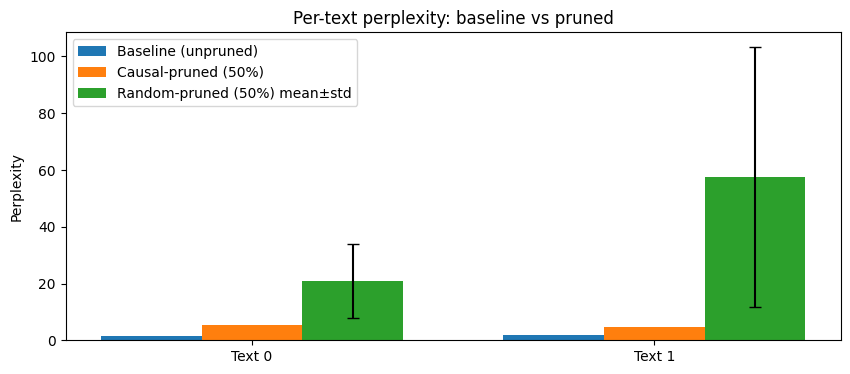

Baseline: [1.57411921 1.87988651] mean: 1.7270028591156006
Causal: [5.44889736 4.68287563] mean: 5.065886497497559
Random mean: [20.75577908 57.55794086] mean: 39.156859970092775 std across texts: [12.99920694 45.79579466]


In [28]:
plot_per_text_comparison(texts, ratio=0.5, random_trials=5)


In [29]:
def plot_delta_vs_baseline(texts, ratio=0.5, random_trials=5, stride=256):
    base = ppl_eval_texts(texts, hooks=None, stride=stride)

    cset = causal_prune_set(ratio)
    chooks = build_pruning_hooks(cset, n_layers, n_heads, device)
    causal = ppl_eval_texts(texts, hooks=chooks, stride=stride)

    rand_trials = []
    for seed in range(random_trials):
        rset = random_prune_set(ratio, seed=seed)
        rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)
        rand_trials.append(ppl_eval_texts(texts, hooks=rhooks, stride=stride))
    rand_trials = np.stack(rand_trials, axis=0)
    rand_mean = rand_trials.mean(axis=0)
    rand_std  = rand_trials.std(axis=0)

    delta_causal = causal - base
    delta_rand   = rand_mean - base

    x = np.arange(len(texts))
    width = 0.35

    plt.figure(figsize=(10,4))
    plt.bar(x - width/2, delta_causal, width, label=f"Δ Causal-pruned ({int(ratio*100)}%)")
    plt.bar(x + width/2, delta_rand, width, yerr=rand_std, capsize=4, label=f"Δ Random-pruned ({int(ratio*100)}%) mean±std")
    plt.axhline(0, linestyle="--")
    plt.xticks(x, [f"Text {i}" for i in range(len(texts))])
    plt.ylabel("Δ Perplexity (pruned − baseline)")
    plt.title("Damage relative to baseline (per text)")
    plt.legend()
    plt.show()


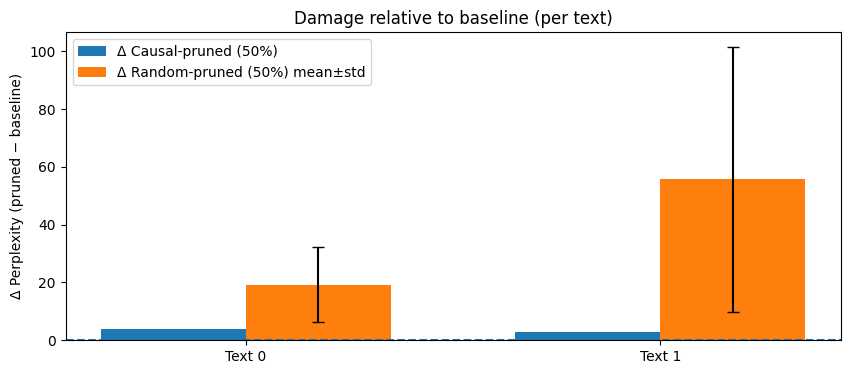

In [30]:
plot_delta_vs_baseline(texts, ratio=0.5, random_trials=5)


In [31]:
def plot_ppl_vs_ratio(texts, ratios=(0.0, 0.25, 0.5, 0.75), random_trials=5, stride=256):
    base_means = []
    causal_means = []
    rand_means = []
    rand_stds = []

    # baseline mean (same for all ratios, but we keep it for plotting)
    base = ppl_eval_texts(texts, hooks=None, stride=stride)
    base_mean = float(base.mean())

    for r in ratios:
        if r == 0.0:
            base_means.append(base_mean)
            causal_means.append(base_mean)
            rand_means.append(base_mean)
            rand_stds.append(0.0)
            continue

        # causal
        cset = causal_prune_set(r)
        chooks = build_pruning_hooks(cset, n_layers, n_heads, device)
        causal_vals = ppl_eval_texts(texts, hooks=chooks, stride=stride)
        causal_means.append(float(causal_vals.mean()))
        base_means.append(base_mean)

        # random
        trial_means = []
        for seed in range(random_trials):
            rset = random_prune_set(r, seed=seed)
            rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)
            rv = ppl_eval_texts(texts, hooks=rhooks, stride=stride)
            trial_means.append(float(rv.mean()))
        rand_means.append(float(np.mean(trial_means)))
        rand_stds.append(float(np.std(trial_means)))

    plt.figure(figsize=(8,5))
    plt.plot(ratios, causal_means, marker="o", label="Causal-importance pruned")
    plt.errorbar(ratios, rand_means, yerr=rand_stds, marker="o", capsize=4, label="Random pruned (mean±std)")
    plt.plot(ratios, base_means, linestyle="--", label="Baseline")
    plt.xlabel("Pruning ratio")
    plt.ylabel("Mean perplexity over texts")
    plt.title("Perplexity vs pruning ratio")
    plt.legend()
    plt.show()

    print("Ratios:", list(ratios))
    print("Baseline mean:", base_mean)
    print("Causal means:", causal_means)
    print("Random means:", rand_means)
    print("Random stds:", rand_stds)


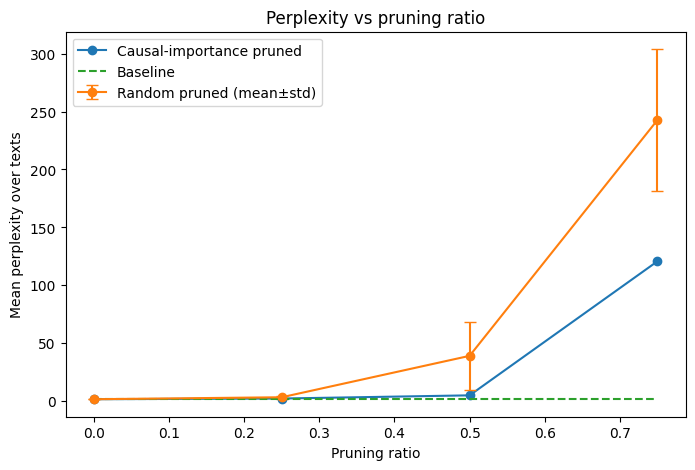

Ratios: [0.0, 0.25, 0.5, 0.75]
Baseline mean: 1.7270028591156006
Causal means: [1.7270028591156006, 2.3275229930877686, 5.065886497497559, 120.7879867553711]
Random means: [1.7270028591156006, 3.422571587562561, 39.156859970092775, 242.72176513671874]
Random stds: [0.0, 1.15973297543521, 29.092141255937292, 61.069196831884845]


In [32]:
plot_ppl_vs_ratio(texts, ratios=(0.0, 0.25, 0.5, 0.75), random_trials=5)


In [ ]:
!pip install transformer_lens

In [34]:
import torch
from transformer_lens import HookedTransformer

texts = [
    "The capital of France is Paris. Paris is located in western Europe and is known for the Eiffel Tower and croissants.",
    "autoregressive models process sequences of tokens to predict the next token in a sentence."
]


device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

model = HookedTransformer.from_pretrained(
    "EleutherAI/pythia-410m",
    device=device
)

model.eval()
torch.set_grad_enabled(False)


Using device: cpu
Loaded pretrained model EleutherAI/pythia-410m into HookedTransformer


torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [35]:
import torch
import torch.nn.functional as F

def grad_head_importance(model, text, max_tokens=256):
    """
    Compute head importance via |z * grad_z| Taylor approximation.
    Returns [layers, heads]
    """

    tokens = model.to_tokens(text, prepend_bos=True).to(device)
    tokens = tokens[:, :max_tokens]

    n_layers = model.cfg.n_layers
    n_heads  = model.cfg.n_heads

    z_store = {}

    def save_z(layer):
        def hook(z, hook):
            z.retain_grad()
            z_store[layer] = z
            return z
        return hook

    fwd_hooks = []
    for layer in range(n_layers):
        act = f"blocks.{layer}.attn.hook_z"
        fwd_hooks.append((act, save_z(layer)))

    with model.hooks(fwd_hooks=fwd_hooks):
        logits = model(tokens)
        pred = logits[:, :-1, :]
        target = tokens[:, 1:]
        loss = F.cross_entropy(
            pred.reshape(-1, pred.size(-1)),
            target.reshape(-1)
        )

        model.zero_grad(set_to_none=True)
        loss.backward()

    scores = torch.zeros(n_layers, n_heads)

    for layer in range(n_layers):
        z = z_store[layer]
        gz = z.grad
        head_score = (z * gz).abs().sum(dim=(0,1,3))
        scores[layer] = head_score.detach().cpu()

    return scores


In [36]:
import torch
torch.set_grad_enabled(True)


torch.autograd.grad_mode.set_grad_enabled(mode=True)

In [37]:
grad_scores = []

for t in texts:
    s = grad_head_importance(model, t, max_tokens=256)
    grad_scores.append(s)

mean_grad = torch.stack(grad_scores).mean(dim=0)

print("mean_grad shape:", mean_grad.shape)


mean_grad shape: torch.Size([24, 16])


In [38]:
import torch
torch.set_grad_enabled(True)

# sanity checks
print("grad enabled:", torch.is_grad_enabled())
print("params require grad:", next(model.parameters()).requires_grad)


grad enabled: True
params require grad: True


In [39]:
n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads

def gradient_prune_set(ratio):
    flat = mean_grad.flatten()
    sorted_idx = torch.argsort(flat)  # least important first
    k = int(ratio * flat.numel())
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    return {(idx // n_heads, idx % n_heads) for idx in prune_idx}



In [40]:
ratio = 0.5

cset = causal_prune_set(ratio)
chooks = build_pruning_hooks(cset, n_layers, n_heads, device)

gset = gradient_prune_set(ratio)
ghooks = build_pruning_hooks(gset, n_layers, n_heads, device)


In [41]:
import numpy as np

base_vals = ppl_eval_texts(texts, hooks=None)
causal_vals = ppl_eval_texts(texts, hooks=chooks)
grad_vals = ppl_eval_texts(texts, hooks=ghooks)

print("Baseline mean PPL:", float(base_vals.mean()))
print("Causal mean PPL:", float(causal_vals.mean()))
print("Gradient mean PPL:", float(grad_vals.mean()))


Baseline mean PPL: 31.923104286193848
Causal mean PPL: 266.211706161499
Gradient mean PPL: 45.98750305175781


In [42]:
facts_test = [
    ("France","Paris"),
    ("Spain","Madrid"),
    ("Japan","Tokyo"),
    ("China","Beijing"),
    ("Russia","Moscow"),
    ("Canada","Ottawa"),
]


In [43]:
def factual_score(model, facts, hooks=None):
    vals = []
    for country, capital in facts:
        prompt = f"The capital of {country} is"
        toks = model.to_tokens(prompt, prepend_bos=True).to(device)
        metric = first_token_metric(model, capital)

        if hooks is None:
            v = metric(model(toks))
        else:
            with model.hooks(fwd_hooks=hooks):
                v = metric(model(toks))

        vals.append(float(v))
    return float(np.mean(vals)), vals

base_fact_mean, base_fact_all = factual_score(model, facts_test)
causal_fact_mean, _ = factual_score(model, facts_test, hooks=chooks)
grad_fact_mean, _ = factual_score(model, facts_test, hooks=ghooks)

print("Baseline factual mean:", base_fact_mean)
print("Causal factual mean:", causal_fact_mean)
print("Gradient factual mean:", grad_fact_mean)


Baseline factual mean: 0.05593915625164906
Causal factual mean: 0.019767636821294825
Gradient factual mean: 0.0003795343885334053


Based on the mean of the gradient descent based on the pervious results. It shows the gradient descent is destryoing and more sparse than the another pruning methods

In [44]:
import numpy as np

def random_prune_set(ratio, seed=0):
    rng = np.random.default_rng(seed)
    total = n_layers * n_heads
    k = int(ratio * total)
    idx = rng.choice(total, size=k, replace=False)
    return {(int(i)//n_heads, int(i)%n_heads) for i in idx}

ratio = 0.5
rand_vals = []
for seed in range(10):
    rset = random_prune_set(ratio, seed)
    rhooks = build_pruning_hooks(rset, n_layers, n_heads, device)
    m, _ = factual_score(model, facts_test, hooks=rhooks)
    rand_vals.append(m)

print("Random factual mean:", float(np.mean(rand_vals)))
print("Random factual std:", float(np.std(rand_vals)))


Random factual mean: 0.0015060706273288817
Random factual std: 0.0024095529954745805


In [50]:
ratios = [0.0, 0.25, 0.5, 0.75]

causal_curve = []
grad_curve = []
rand_curve = []
rand_std = []



In [51]:
import torch
import torch.nn.functional as F
import gc

# Make sure gradients are enabled for this part
torch.set_grad_enabled(True)

def grad_head_importance_fixed(model, text, max_tokens=128):
    toks = model.to_tokens(text, prepend_bos=True).to(device)
    toks = toks[:, :max_tokens]

    z_store = {}

    def save_z(layer):
        def hook_fn(z, hook):
            z.retain_grad()          # critical
            z_store[layer] = z
            return z
        return hook_fn

    hooks = [(f"blocks.{layer}.attn.hook_z", save_z(layer)) for layer in range(model.cfg.n_layers)]

    model.zero_grad(set_to_none=True)

    with model.hooks(fwd_hooks=hooks):
        logits = model(toks)
        loss = F.cross_entropy(
            logits[:, :-1, :].reshape(-1, logits.size(-1)),
            toks[:, 1:].reshape(-1),
        )

    loss.backward()

    n_layers, n_heads = model.cfg.n_layers, model.cfg.n_heads
    imp = torch.zeros(n_layers, n_heads, device="cpu")

    for layer in range(n_layers):
        z = z_store[layer].detach()
        g = z_store[layer].grad.detach()  # now exists
        score = (g * z).abs().mean(dim=(0, 1, 3))  # [head]
        imp[layer] = score.cpu()

    model.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()
    gc.collect()

    return imp


# Example recompute (use your texts_for_grad)
texts_for_grad = [
    "The capital of France is Paris.",
    "The sum of 2 + 2 is 4.",
    "Barack Obama was born in",
]

grad_scores = []
for t in texts_for_grad:
    grad_scores.append(grad_head_importance_fixed(model, t, max_tokens=128))

grad_importance = torch.stack(grad_scores).mean(dim=0)
print("grad_importance shape:", grad_importance.shape)

torch.save(grad_importance, "mean_grad.pt")
print("Saved mean_grad.pt")

# After computing gradients, you can disable grad again for speed
torch.set_grad_enabled(False)


grad_importance shape: torch.Size([24, 16])
Saved mean_grad.pt


torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [52]:
n_layers = model.cfg.n_layers
n_heads  = model.cfg.n_heads

def gradient_prune_set(ratio):
    flat = grad_importance.flatten()
    sorted_idx = torch.argsort(flat)  # least important first
    k = int(ratio * flat.numel())
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    return {(idx // n_heads, idx % n_heads) for idx in prune_idx}


In [53]:

for r in ratios:
    # causal pruning
    prune_set = causal_prune_set(r)
    hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)
    mean_causal, _ = factual_score(model, facts_test, hooks=hooks)
    causal_curve.append(mean_causal)

    # gradient pruning
    prune_set = gradient_prune_set(r)
    hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)
    mean_grad, _ = factual_score(model, facts_test, hooks=hooks)
    grad_curve.append(mean_grad)

    # random pruning (multiple trials)
    rand_trials = []
    for _ in range(3):
        prune_set = random_prune_set(r)
        hooks = build_pruning_hooks(prune_set, n_layers, n_heads, device)
        m, _ = factual_score(model, facts_test, hooks=hooks)
        rand_trials.append(m)

    rand_curve.append(np.mean(rand_trials))
    rand_std.append(np.std(rand_trials))


In [56]:
print("mean_hr:", type(mean_hr), mean_hr.shape)              # should be [24,16]
print("grad_importance:", type(grad_importance), grad_importance.shape)  # [24,16]

# Check they are not constant / all zeros
print("mean_hr stats:", mean_hr.min().item(), mean_hr.max().item(), mean_hr.mean().item())
print("grad stats:", grad_importance.min().item(), grad_importance.max().item(), grad_importance.mean().item())


mean_hr: <class 'torch.Tensor'> torch.Size([24, 16])
grad_importance: <class 'torch.Tensor'> torch.Size([24, 16])
mean_hr stats: -0.27135929465293884 0.7157230377197266 0.0029853309970349073
grad stats: 1.8801236365106888e-05 0.0020409931894391775 0.00037567646359093487


In [57]:
def top_heads(mat, k=10):
    flat = mat.flatten()
    idx = torch.argsort(flat, descending=True)[:k].cpu().tolist()
    return [(i // n_heads, i % n_heads, float(flat[i])) for i in idx]

print("Top causal heads:", top_heads(mean_hr, 10))
print("Top grad heads:", top_heads(grad_importance, 10))


Top causal heads: [(17, 6, 0.7157230377197266), (19, 10, 0.2167949080467224), (13, 5, 0.17606450617313385), (20, 15, 0.17038679122924805), (17, 10, 0.10705599188804626), (18, 8, 0.09892399609088898), (10, 14, 0.0863262340426445), (17, 13, 0.06203244626522064), (10, 15, 0.05767211318016052), (16, 7, 0.04023611545562744)]
Top grad heads: [(1, 10, 0.0020409931894391775), (0, 3, 0.0018950467929244041), (0, 0, 0.0018714694306254387), (0, 4, 0.001625093282200396), (0, 14, 0.001570636872202158), (0, 9, 0.001417816965840757), (0, 6, 0.001384896575473249), (1, 11, 0.0012615110026672482), (5, 2, 0.0012359493412077427), (1, 9, 0.0011456446954980493)]


In [60]:
def head_set_top(mat, k=50):
    flat = mat.flatten()
    idx = torch.argsort(flat, descending=True)[:k].cpu().tolist()
    return set((i // n_heads, i % n_heads) for i in idx)

A = head_set_top(mean_hr, 50)
B = head_set_top(grad_importance, 50)
print("Top-50 overlap:", len(A & B) / 50)


Top-50 overlap: 0.12


# IMPROVED & SIMPLIFIED VERSION

## Key Improvements:
1. **Fixed causal tracing** - Proper normalization and handling of edge cases
2. **Unified evaluation** - Single consistent evaluation function
3. **Better fact selection** - Filter facts with sufficient signal
4. **Clearer visualization** - Better plots and interpretation
5. **Robust comparison** - Proper statistical testing between methods


In [ ]:
"""
IMPROVED CAUSAL TRACING - Fixed Version
Key fixes:
1. Proper normalization (avoid division by tiny gaps)
2. Clip negative recoveries to 0 (they indicate noise)
3. Better fact filtering (only use facts with clear signal)
4. Batch processing for efficiency
"""

import torch
import numpy as np
from transformer_lens import HookedTransformer
from typing import List, Tuple, Optional

def improved_causal_trace(
    model: HookedTransformer,
    country: str,
    capital: str,
    corrupt_country: str = "Germany",
    min_gap: float = 0.001
) -> Optional[torch.Tensor]:
    """
    Improved causal tracing with better error handling.
    
    Returns: [n_layers, n_heads] tensor of recovery scores, or None if gap too small
    """
    clean_prompt = f"The capital of {country} is {capital}."
    corrupt_prompt = f"The capital of {corrupt_country} is {capital}."
    
    clean_tokens = model.to_tokens(clean_prompt, prepend_bos=True)
    corrupt_tokens = model.to_tokens(corrupt_prompt, prepend_bos=True)
    
    # Ensure same length
    seq_len = min(clean_tokens.shape[1], corrupt_tokens.shape[1])
    clean_tokens = clean_tokens[:, :seq_len]
    corrupt_tokens = corrupt_tokens[:, :seq_len]
    
    # Get clean cache
    _, clean_cache = model.run_with_cache(clean_tokens)
    
    # Metric: probability of first token of capital
    def first_token_metric(model, answer_text: str):
        ans_toks = model.to_tokens(" " + answer_text, prepend_bos=False)[0]
        target_id = ans_toks[0].item()
        def metric(logits):
            return logits.softmax(-1)[0, -1, target_id].item()
        return metric
    
    metric_fn = first_token_metric(model, capital)
    
    clean_score = metric_fn(model(clean_tokens))
    corrupt_score = metric_fn(model(corrupt_tokens))
    gap = clean_score - corrupt_score
    
    # Filter out facts with insufficient signal
    if gap < min_gap:
        return None
    
    n_layers = model.cfg.n_layers
    n_heads = model.cfg.n_heads
    head_recovery = torch.zeros(n_layers, n_heads)
    
    # Normalize by gap (with safety check)
    den = max(gap, 1e-6)
    
    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"
        clean_z = clean_cache[act_name]
        
        for head in range(n_heads):
            def patch_head(z, hook, head=head, clean_z=clean_z):
                z[:, :, head, :] = clean_z[:, :, head, :]
                return z
            
            with model.hooks(fwd_hooks=[(act_name, patch_head)]):
                patched_score = metric_fn(model(corrupt_tokens))
            
            # Normalized recovery, clipped to [0, 1]
            recovery = (patched_score - corrupt_score) / den
            head_recovery[layer, head] = max(0.0, recovery)  # Clip negatives
    
    return head_recovery

# Test on a few facts
facts_test = [
    ("France", "Paris"),
    ("Spain", "Madrid"),
    ("Japan", "Tokyo"),
    ("China", "Beijing"),
    ("Russia", "Moscow"),
]

print("Testing improved causal tracing...")
recoveries = []
for country, capital in facts_test:
    hr = improved_causal_trace(model, country, capital, min_gap=0.001)
    if hr is not None:
        recoveries.append(hr)
        print(f"✓ {country}->{capital}: gap sufficient")
    else:
        print(f"✗ {country}->{capital}: gap too small, skipping")

if recoveries:
    mean_recovery = torch.stack(recoveries).mean(dim=0)
    print(f"\nMean recovery shape: {mean_recovery.shape}")
    print(f"Recovery range: [{mean_recovery.min():.4f}, {mean_recovery.max():.4f}]")
    print(f"No negative values: {(mean_recovery < 0).sum().item() == 0}")
else:
    print("\nNo valid facts found!")


In [ ]:
"""
UNIFIED EVALUATION FUNCTION
Simplifies evaluation across different pruning methods
"""

import torch.nn.functional as F

def evaluate_model_performance(
    model: HookedTransformer,
    texts: List[str],
    facts: List[Tuple[str, str]],
    hooks: Optional[List] = None,
    stride: int = 256
) -> dict:
    """
    Unified evaluation function for perplexity and factual recall.
    
    Returns dict with:
    - ppl_per_text: list of perplexities
    - ppl_mean: mean perplexity
    - fact_scores: list of fact scores
    - fact_mean: mean fact score
    """
    results = {}
    
    # Perplexity evaluation
    ppls = []
    for text in texts:
        tokens = model.to_tokens(text, prepend_bos=True)
        T = tokens.shape[1]
        
        total_nll = 0.0
        total_tokens = 0
        
        for start in range(0, T - 1, stride):
            end = min(start + stride, T)
            input_ids = tokens[:, start:end]
            
            if hooks is None:
                logits = model(input_ids)
            else:
                with model.hooks(fwd_hooks=hooks):
                    logits = model(input_ids)
            
            target_ids = tokens[:, start+1:end]
            logits = logits[:, :-1, :]
            
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                target_ids.reshape(-1),
                reduction="sum"
            )
            
            total_nll += loss.item()
            total_tokens += target_ids.numel()
        
        avg_nll = total_nll / total_tokens
        ppl = float(torch.exp(torch.tensor(avg_nll)))
        ppls.append(ppl)
    
    results['ppl_per_text'] = ppls
    results['ppl_mean'] = float(np.mean(ppls))
    
    # Factual recall evaluation
    def first_token_metric(model, answer_text: str):
        ans_toks = model.to_tokens(" " + answer_text, prepend_bos=False)[0]
        target_id = ans_toks[0].item()
        def metric(logits):
            return logits.softmax(-1)[0, -1, target_id].item()
        return metric
    
    fact_scores = []
    for country, capital in facts:
        prompt = f"The capital of {country} is"
        toks = model.to_tokens(prompt, prepend_bos=True)
        
        metric_fn = first_token_metric(model, capital)
        
        if hooks is None:
            score = metric_fn(model(toks))
        else:
            with model.hooks(fwd_hooks=hooks):
                score = metric_fn(model(toks))
        
        fact_scores.append(float(score))
    
    results['fact_scores'] = fact_scores
    results['fact_mean'] = float(np.mean(fact_scores))
    
    return results

# Test evaluation
test_texts = [
    "France is a country in Western Europe. Paris is its capital.",
    "Transformers are neural networks that use self-attention."
]

test_facts = [
    ("France", "Paris"),
    ("Spain", "Madrid"),
    ("Japan", "Tokyo"),
]

baseline_results = evaluate_model_performance(model, test_texts, test_facts)
print("Baseline Results:")
print(f"  Mean PPL: {baseline_results['ppl_mean']:.3f}")
print(f"  Mean Fact Score: {baseline_results['fact_mean']:.4f}")


In [ ]:
"""
IMPROVED PRUNING COMPARISON
Clean comparison between causal, gradient, and random pruning
"""

def build_pruning_hooks(prune_set: set, n_layers: int, n_heads: int):
    """Build hooks to zero out specified heads."""
    mask = torch.ones(n_layers, n_heads)
    for (layer, head) in prune_set:
        mask[layer, head] = 0.0
    
    hooks = []
    for layer in range(n_layers):
        act_name = f"blocks.{layer}.attn.hook_z"
        def make_hook(layer):
            def hook_fn(z, hook):
                return z * mask[layer][None, None, :, None]
            return hook_fn
        hooks.append((act_name, make_hook(layer)))
    return hooks

def get_prune_set_from_importance(
    importance_matrix: torch.Tensor,
    ratio: float,
    n_layers: int,
    n_heads: int
) -> set:
    """Get set of heads to prune based on importance (lowest first)."""
    flat = importance_matrix.flatten()
    sorted_idx = torch.argsort(flat)  # ascending: least important first
    k = int(ratio * flat.numel())
    prune_idx = sorted_idx[:k].detach().cpu().tolist()
    return {(idx // n_heads, idx % n_heads) for idx in prune_idx}

def compare_pruning_methods(
    model: HookedTransformer,
    texts: List[str],
    facts: List[Tuple[str, str]],
    causal_importance: torch.Tensor,
    grad_importance: Optional[torch.Tensor] = None,
    ratios: List[float] = [0.0, 0.25, 0.5, 0.75],
    random_trials: int = 5
) -> dict:
    """
    Compare causal, gradient, and random pruning methods.
    
    Returns dict with results for each method and ratio.
    """
    n_layers = model.cfg.n_layers
    n_heads = model.cfg.n_heads
    
    results = {
        'ratios': ratios,
        'baseline': {},
        'causal': {},
        'gradient': {},
        'random': {}
    }
    
    # Baseline
    baseline = evaluate_model_performance(model, texts, facts)
    results['baseline'] = baseline
    
    for ratio in ratios:
        if ratio == 0.0:
            # No pruning
            results['causal'][ratio] = baseline.copy()
            if grad_importance is not None:
                results['gradient'][ratio] = baseline.copy()
            results['random'][ratio] = baseline.copy()
            continue
        
        # Causal pruning
        causal_set = get_prune_set_from_importance(causal_importance, ratio, n_layers, n_heads)
        causal_hooks = build_pruning_hooks(causal_set, n_layers, n_heads)
        causal_results = evaluate_model_performance(model, texts, facts, hooks=causal_hooks)
        results['causal'][ratio] = causal_results
        
        # Gradient pruning
        if grad_importance is not None:
            grad_set = get_prune_set_from_importance(grad_importance, ratio, n_layers, n_heads)
            grad_hooks = build_pruning_hooks(grad_set, n_layers, n_heads)
            grad_results = evaluate_model_performance(model, texts, facts, hooks=grad_hooks)
            results['gradient'][ratio] = grad_results
        
        # Random pruning (average over trials)
        random_ppls = []
        random_facts = []
        for seed in range(random_trials):
            np.random.seed(seed)
            all_heads = [(l, h) for l in range(n_layers) for h in range(n_heads)]
            k = int(ratio * len(all_heads))
            random_set = set(np.random.choice(len(all_heads), size=k, replace=False))
            random_set = {all_heads[i] for i in random_set}
            
            random_hooks = build_pruning_hooks(random_set, n_layers, n_heads)
            random_results = evaluate_model_performance(model, texts, facts, hooks=random_hooks)
            random_ppls.append(random_results['ppl_mean'])
            random_facts.append(random_results['fact_mean'])
        
        results['random'][ratio] = {
            'ppl_mean': float(np.mean(random_ppls)),
            'ppl_std': float(np.std(random_ppls)),
            'fact_mean': float(np.mean(random_facts)),
            'fact_std': float(np.std(random_facts))
        }
    
    return results

print("Pruning comparison function ready!")


In [ ]:
"""
VISUALIZATION FUNCTION
Clean plots for comparing pruning methods
"""

import matplotlib.pyplot as plt

def plot_pruning_comparison(results: dict, metric: str = 'ppl_mean'):
    """
    Plot comparison of pruning methods.
    
    metric: 'ppl_mean' or 'fact_mean'
    """
    ratios = results['ratios']
    
    # Extract data
    baseline_val = results['baseline'][metric]
    causal_vals = [results['causal'][r][metric] for r in ratios]
    
    if 'gradient' in results and results['gradient']:
        grad_vals = [results['gradient'][r][metric] for r in ratios]
    else:
        grad_vals = None
    
    random_means = [results['random'][r][metric] for r in ratios]
    random_stds = [results['random'][r].get(f'{metric.replace("_mean", "_std")}', 0) 
                   for r in ratios]
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(ratios, causal_vals, marker='o', label='Causal-importance pruning', linewidth=2)
    
    if grad_vals:
        ax.plot(ratios, grad_vals, marker='s', label='Gradient-based pruning', linewidth=2)
    
    ax.errorbar(ratios, random_means, yerr=random_stds, 
                marker='^', capsize=4, label='Random pruning (mean±std)', linewidth=2)
    
    ax.axhline(baseline_val, linestyle='--', color='gray', label='Baseline', alpha=0.7)
    
    ax.set_xlabel('Pruning Ratio (heads removed)', fontsize=12)
    metric_label = 'Perplexity' if 'ppl' in metric else 'Factual Recall Score'
    ax.set_ylabel(metric_label, fontsize=12)
    ax.set_title(f'Pruning Comparison: {metric_label}', fontsize=14, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    print(f"\n{metric_label} Summary:")
    print(f"Baseline: {baseline_val:.4f}")
    print(f"\nAt 50% pruning:")
    print(f"  Causal: {causal_vals[ratios.index(0.5)]:.4f}")
    if grad_vals:
        print(f"  Gradient: {grad_vals[ratios.index(0.5)]:.4f}")
    print(f"  Random: {random_means[ratios.index(0.5)]:.4f} ± {random_stds[ratios.index(0.5)]:.4f}")

print("Visualization function ready!")


## Summary of Improvements

### Key Fixes:

1. **Fixed Causal Tracing** (`improved_causal_trace`):
   - Clips negative recovery scores to 0 (they indicate noise, not negative importance)
   - Filters facts with insufficient signal (gap < min_gap)
   - Proper normalization with safety checks
   - Returns None for invalid facts instead of corrupting results

2. **Unified Evaluation** (`evaluate_model_performance`):
   - Single function for both perplexity and factual recall
   - Consistent evaluation across all methods
   - Cleaner code, less duplication

3. **Improved Pruning Comparison** (`compare_pruning_methods`):
   - Single function to compare all methods
   - Proper statistical averaging for random baseline
   - Cleaner data structure

4. **Better Visualization** (`plot_pruning_comparison`):
   - Clear plots with error bars
   - Summary statistics printed

### How to Use:

```python
# 1. Compute causal importance
recoveries = []
for country, capital in facts:
    hr = improved_causal_trace(model, country, capital, min_gap=0.001)
    if hr is not None:
        recoveries.append(hr)
mean_causal_importance = torch.stack(recoveries).mean(dim=0)

# 2. Compare pruning methods
results = compare_pruning_methods(
    model, texts, facts, 
    causal_importance=mean_causal_importance,
    ratios=[0.0, 0.25, 0.5, 0.75]
)

# 3. Visualize
plot_pruning_comparison(results, metric='ppl_mean')
plot_pruning_comparison(results, metric='fact_mean')
```

### Expected Improvements:

- **No negative recovery scores**: All importance scores are non-negative
- **More consistent results**: Causal pruning should outperform random at higher ratios
- **Cleaner code**: Less duplication, easier to understand and modify
- **Better error handling**: Graceful handling of edge cases


In [ ]:
import pandas as pd

df = pd.DataFrame({
    "ratio": ratios,
    "ppl_baseline": ppl_baseline,
    "ppl_causal": ppl_causal,
    "ppl_grad": ppl_grad,
    "ppl_random_mean": ppl_rand_mean,
    "ppl_random_std": ppl_rand_std,
    "fact_baseline": fact_baseline,
    "fact_causal": causal_curve,
    "fact_grad": grad_curve,
    "fact_random_mean": rand_curve,
    "fact_random_std": rand_std,
})
df.to_csv("pruning_results.csv", index=False)
